In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import joblib
import re
import json
import math
import time
import random
from collections import Counter
from scipy.sparse import hstack, vstack
import matplotlib.pyplot as plt
import shap
shap.initjs()

svm_model = joblib.load("/content/drive/MyDrive/Phishing_Email/models/nlp_svm_linear_model.pkl")
rf_model = joblib.load("/content/drive/MyDrive/Phishing_Email/models/nlp_rf_model.pkl")
tfid = joblib.load("/content/drive/MyDrive/Phishing_Email/nlp_features/tfidf_features.pkl")
nlp_scaler = joblib.load("/content/drive/MyDrive/Phishing_Email/nlp_features/nlp_scaler.pkl")
nlp_feature_names = joblib.load("/content/drive/MyDrive/Phishing_Email/nlp_features/nlp_feature_names.pkl")

tfid_feature_names = tfid.get_feature_names_out().tolist()
all_feature_names  = tfid_feature_names + nlp_feature_names

print("Models and features loaded.")
print(f"Total features: {len(all_feature_names)}")

Models and features loaded.
Total features: 5009


In [ ]:
import re
import html
import string

def preprocess_text(text):
    text = html.unescape(text)
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'\S+@\S+', ' ', text)
    text = re.sub(r'\b(?:\d{1,3}\.){3}\d{1,3}\b', ' ', text)
    text = re.sub(r'\d+', ' ', text)
    text = text.translate(str.maketrans('', '', string.punctuation))
    text = re.sub(r'[^a-z\s]', ' ', text)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

def extract_nlp_features(precomputed_row: dict):
    features = {col: float(precomputed_row.get(col, 0)) for col in nlp_feature_names}
    features_df = pd.DataFrame([features])
    scaled_features = nlp_scaler.transform(features_df[nlp_feature_names])
    return scaled_features

def get_combined_features(email_text, precomputed_row=None):
    processed_text = preprocess_text(email_text)
    tfidf_vector = tfid.transform([processed_text])

    if precomputed_row is not None:
        nlp_features = extract_nlp_features(precomputed_row)
    else:
        zero_row = {col: 0 for col in nlp_feature_names}
        features_df = pd.DataFrame([zero_row])
        nlp_features = nlp_scaler.transform(features_df[nlp_feature_names])

    return hstack([tfidf_vector, nlp_features])

print("Feature engineering pipeline ready.")
print("Note: NLP features are read from the preprocessed CSV - no recomputation.")

Feature engineering pipeline ready.
Note: NLP features are read from the preprocessed CSV - no recomputation.


In [ ]:
test_df = pd.read_csv("/content/drive/MyDrive/Phishing_Email/final_dataset/Enron_preprocessed.csv")

if "clean_text" in test_df.columns and "body" not in test_df.columns:
    test_df = test_df.rename(columns={"clean_text": "body"})
    print("Renamed 'clean_text' column to 'body'.")

EMAIL_COLUMN = "body"
LABEL_COLUMN = "label"

print(f"Test set size: {len(test_df)}")

background_sample = test_df.sample(n=100, random_state=42)
background_emails = background_sample[EMAIL_COLUMN].tolist()

background_sparse = vstack([
    get_combined_features(email, row)
    for email, (_, row) in zip(background_emails, background_sample.iterrows())
])

background_dense = background_sparse.toarray()

svm_explainer = shap.LinearExplainer(
    svm_model,
    background_sparse
)

rf_explainer = shap.TreeExplainer(
    rf_model,
    data=background_dense,
    model_output="probability"
)

background_data = {
    "svm": background_sparse,
    "rf": background_dense
}

print(f"Background dense shape: {background_dense.shape}")
print(f"Background sparse shape: {background_sparse.shape}")

print("SHAP explainers ready")


Renamed 'clean_text' column to 'body'.
Test set size: 28256
Background dense shape: (100, 5009)
Background sparse shape: (100, 5009)
SHAP explainers ready


In [ ]:
W_SVM         = 0.5
W_RF          = 0.5
ENS_THRESHOLD = 0.5

print("=" * 60)
print("ENSEMBLE CONFIGURATION (cite in paper Section VI-C)")
print("=" * 60)
print(f"  Formula : P_ens = {W_SVM}·P_SVM + {W_RF}·P_RF")
print(f"  Threshold: {ENS_THRESHOLD}")
print(f"  Both weights set on AVN training data only.")
print(f"  No Enron labels used → result is strict zero-shot.")
print("=" * 60)

def _get_svm_prob_phishing(X_sparse):
    score = svm_model.decision_function(X_sparse)[0]
    return float(1.0 / (1.0 + np.exp(-score)))

def _get_rf_prob_phishing(X_dense):
    return float(rf_model.predict_proba(X_dense)[0][1])

def compute_final_verdict(svm_prob_phishing, rf_prob_phishing):
    avg_p       = W_SVM * svm_prob_phishing + W_RF * rf_prob_phishing
    final_label = "Phishing" if avg_p >= ENS_THRESHOLD else "Legitimate"
    final_conf  = round(avg_p * 100, 1) if final_label == "Phishing" else round((1 - avg_p) * 100, 1)
    svm_label = "Phishing" if svm_prob_phishing >= 0.5 else "Legitimate"
    rf_label  = "Phishing" if rf_prob_phishing  >= 0.5 else "Legitimate"
    return {
        "final_label":      final_label,
        "final_confidence": final_conf,
        "models_agree":     svm_label == rf_label,
    }

from scipy.stats import spearmanr

def _weighted_jaccard(v1, v2, feature_names, top_n=20):
    pairs1 = sorted(zip(feature_names, v1), key=lambda x: x[1], reverse=True)[:top_n]
    pairs2 = sorted(zip(feature_names, v2), key=lambda x: x[1], reverse=True)[:top_n]

    w1 = {f: abs(s) for f, s in pairs1}
    w2 = {f: abs(s) for f, s in pairs2}

    sum1, sum2 = sum(w1.values()) or 1, sum(w2.values()) or 1
    w1 = {f: v / sum1 for f, v in w1.items()}
    w2 = {f: v / sum2 for f, v in w2.items()}

    all_feats = set(w1) | set(w2)
    intersection = sum(min(w1.get(f, 0), w2.get(f, 0)) for f in all_feats)
    union        = sum(max(w1.get(f, 0), w2.get(f, 0)) for f in all_feats)
    return intersection / union if union > 0 else 0.0

def _rank_correlation(v1, v2):
    rho, _ = spearmanr(v1, v2)
    if np.isnan(rho):
        rho = 0.0
    return (float(rho) + 1.0) / 2.0

def _cosine_similarity(v1, v2):
    norm1, norm2 = np.linalg.norm(v1), np.linalg.norm(v2)
    if norm1 == 0 or norm2 == 0:
        return 0.5
    cos = float(np.dot(v1, v2) / (norm1 * norm2))
    return (cos + 1.0) / 2.0

def _topk_stability(v1, v2, feature_names, k_values=(5, 10, 15, 20, 25, 30)):
    jaccards = []
    for k in k_values:
        set1 = {f for f, _ in sorted(zip(feature_names, v1), key=lambda x: x[1], reverse=True)[:k]}
        set2 = {f for f, _ in sorted(zip(feature_names, v2), key=lambda x: x[1], reverse=True)[:k]}
        union = set1 | set2
        jaccards.append(len(set1 & set2) / len(union) if union else 0.0)
    return float(np.mean(jaccards))

def compute_shap_values(combined_features_dense, combined_features_sparse):
    def safe_shap(vals):
        arr = np.asarray(vals).squeeze()
        if isinstance(vals, list) and len(vals) > 1:
            arr = np.asarray(vals[1]).squeeze()
        if arr.ndim > 1:
            arr = arr[..., -1] if arr.shape[-1] in [1, 2] else arr.flatten()
        return np.asarray(arr, dtype=float).ravel()

    svm_shap = safe_shap(svm_explainer.shap_values(combined_features_sparse))
    rf_shap  = safe_shap(rf_explainer.shap_values(combined_features_dense, check_additivity=False))

    def get_top_features(shap_vals, top_n=20):
        pairs   = list(zip(all_feature_names, shap_vals))
        top_pos = sorted(pairs, key=lambda x: x[1], reverse=True)[:top_n]
        top_neg = sorted(pairs, key=lambda x: x[1])[:top_n]
        return top_pos, top_neg

    svm_top_pos, svm_top_neg = get_top_features(svm_shap)
    rf_top_pos,  rf_top_neg  = get_top_features(rf_shap)

    raw_overlap     = len({f for f, _ in svm_top_pos} & {f for f, _ in rf_top_pos})
    raw_overlap_pct = round(raw_overlap / 20 * 100, 1)

    wj   = _weighted_jaccard(svm_shap, rf_shap, all_feature_names, top_n=20)
    rc   = _rank_correlation(svm_shap, rf_shap)
    cs   = _cosine_similarity(svm_shap, rf_shap)
    stab = _topk_stability(svm_shap, rf_shap, all_feature_names)

    shap_consistency = round(np.mean([wj, rc, cs, stab]) * 100, 1)

    return {
        "svm_shap":    svm_shap,     "rf_shap":    rf_shap,
        "svm_top_pos": svm_top_pos,  "svm_top_neg": svm_top_neg,
        "rf_top_pos":  rf_top_pos,   "rf_top_neg":  rf_top_neg,
        "shap_consistency":      shap_consistency,
        "raw_overlap_pct":       raw_overlap_pct,
        "weighted_jaccard":      round(wj  * 100, 1),
        "rank_correlation":      round(rc  * 100, 1),
        "cosine_similarity":     round(cs  * 100, 1),
        "topk_stability":        round(stab * 100, 1),
    }

def compute_explanation_confidence(svm_label, rf_label, svm_prob_phishing, rf_prob_phishing, concept_agreement_score, shap_consistency):
    prediction_agreement   = 100.0 if svm_label == rf_label else 0.0
    probability_similarity = round((1 - abs(svm_prob_phishing - rf_prob_phishing)) * 100, 1)
    overall_confidence = round(
        prediction_agreement    * 0.25 +
        probability_similarity  * 0.25 +
        concept_agreement_score * 0.25 +
        shap_consistency        * 0.25, 1
    )
    return {
        "prediction_agreement":   prediction_agreement,
        "probability_similarity": probability_similarity,
        "concept_agreement":      concept_agreement_score,
        "shap_consistency":       shap_consistency,
        "overall_confidence":     overall_confidence,
    }

print("Core ML functions ready.")
_asr_denom    = globals().get("valid_asr_denominator", None)
_syn_evaded   = globals().get("synonym_evaded",        None)
_hom_evaded   = globals().get("homoglyph_evaded",      None)

print("\n" + "=" * 62)
print("  ADVERSARIAL VULNERABILITY PROBE - RUNTIME ASR SUMMARY")
print("=" * 62)

if _asr_denom is None:
    print("  ⚠  Adversarial probe cell has not been run yet.")
else:
    print(f"  ASR denominator (correctly classified before attack): {_asr_denom} / 5")
    print(f"  Synonym substitution evaded    : {_syn_evaded} / {_asr_denom}")
    if _asr_denom > 0:
        print(f"  Synonym ASR                    : {_syn_evaded / _asr_denom * 100:.1f}%")
    print(f"  Homoglyph substitution evaded  : {_hom_evaded} / {_asr_denom}")
    if _asr_denom > 0:
        print(f"  Homoglyph ASR                  : {_hom_evaded / _asr_denom * 100:.1f}%")
print()"

ENSEMBLE CONFIGURATION (cite in paper Section VI-C)
  Formula : P_ens = 0.5·P_SVM + 0.5·P_RF
  Threshold: 0.5
  Both weights set on AVN training data only.
  No Enron labels used → result is strict zero-shot.
Core ML functions ready.
  compute_shap_values now returns enhanced SHAP consistency metrics:
    shap_consistency  - composite (weighted Jaccard + rank corr + cosine + top-k stability)
    raw_overlap_pct   - original top-20 overlap % (backward compat)
    weighted_jaccard, rank_correlation, cosine_similarity, topk_stability - individual scores

  ADVERSARIAL VULNERABILITY PROBE - RUNTIME ASR SUMMARY
  ⚠  Adversarial probe cell has not been run yet.
     Run the adversarial probe cell to populate ASR values.
     (valid_asr_denominator / synonym_evaded / homoglyph_evaded)

  NOTE: cite only the runtime values above in the paper.
  Do NOT use hardcoded 100% ASR unless runtime confirms it.


In [ ]:
import json
import os
KB_PATH = "/content/drive/MyDrive/Phishing_Email/notebooks/phishing_explanation_kb.json"
_kb_cache = None
def load_kb(path=KB_PATH):
    """Load (and cache) the explanation knowledge base from disk."""
    global _kb_cache
    if _kb_cache is None:
        if not os.path.exists(path):
            raise FileNotFoundError(
                f"Knowledge base not found at '{path}'. "
                f"Upload phishing_explanation_kb.json or update KB_PATH."
            )
        with open(path, "r", encoding="utf-8") as f:
            _kb_cache = json.load(f)
    return _kb_cache
DEFAULT_EXPLANATIONS = {
    "bidirectional": "No dominant pattern could be matched to the knowledge base.",
    "contrastive": "No dominant pattern could be matched to the knowledge base.",
    "counterfactual": "No dominant pattern could be matched to the knowledge base.",
}
DEFAULT_RECOMMENDATIONS = [
    "Avoid clicking suspicious links.",
    "Do not share credentials.",
]
def _match_concept(feature_name, kb):
    """
    Try to map a single SHAP feature name to:
      - a named "concept" (text-pattern based, e.g. 'Urgency / Pressure Language'), or
      - an NLP meta-feature explanation (e.g. 'url_like_count'), or
      - None if nothing matches.
    Returns (kind, name, payload) where kind is "concept" or "nlp_feature",
    and payload is the matched concept dict / nlp-feature dict.
    """
    fname = str(feature_name).lower().strip()
    nlp_bank = kb.get("nlp_feature_explanations", {})
    if fname in nlp_bank:
        return ("nlp_feature", fname, nlp_bank[fname])
    for concept in kb.get("concepts", []):
        if fname in concept.get("keywords", []):
            return ("concept", concept["name"], concept)
    for concept in kb.get("concepts", []):
        keywords = concept.get("keywords", [])
        if any(kw in fname or fname in kw for kw in keywords if len(kw) > 3):
            return ("concept", concept["name"], concept)
    return (None, None, None)
def _extract_concepts(top_pos, top_neg, kb, max_per_direction=10):
    """
    Given a model's top positive (phishing-leaning) and top negative
    (legitimate-leaning) SHAP feature/value pairs, return:
      phishing_concepts, legit_concepts  -> lists of concept names
      phishing_nlp_phrases, legit_nlp_phrases -> short noun phrases from nlp features
    """
    phishing_concepts, legit_concepts = [], []
    phishing_nlp, legit_nlp = [], []
    for fname, shap_val in top_pos[:max_per_direction]:
        if shap_val <= 0:
            continue
        kind, name, payload = _match_concept(fname, kb)
        if kind == "concept" and name not in phishing_concepts:
            phishing_concepts.append(name)
        elif kind == "nlp_feature":
            phishing_nlp.append(payload.get("increases_risk_phrase", fname))
    for fname, shap_val in top_neg[:max_per_direction]:
        if shap_val >= 0:
            continue
        kind, name, payload = _match_concept(fname, kb)
        if kind == "concept" and name not in legit_concepts:
            legit_concepts.append(name)
        elif kind == "nlp_feature":
            legit_nlp.append(payload.get("decreases_risk_phrase", fname))
    return phishing_concepts, legit_concepts, phishing_nlp, legit_nlp
def _build_concept_results(svm_top_pos, svm_top_neg, rf_top_pos, rf_top_neg, kb):
    """
    Mirrors the shape the Groq version produced:
      common_concepts / svm_only_concepts / rf_only_concepts / concept_reasonings /
      concept_agreement_score
    "Common" = same concept, same direction (phishing-leaning), seen in both models.
    """
    svm_phish, svm_legit, svm_phish_nlp, svm_legit_nlp = _extract_concepts(svm_top_pos, svm_top_neg, kb)
    rf_phish, rf_legit, rf_phish_nlp, rf_legit_nlp = _extract_concepts(rf_top_pos, rf_top_neg, kb)
    svm_set, rf_set = set(svm_phish), set(rf_phish)
    common = [c for c in svm_phish if c in rf_set]
    svm_only = [c for c in svm_phish if c not in rf_set]
    rf_only = [c for c in rf_phish if c not in svm_set]
    total = len(common) + len(svm_only) + len(rf_only)
    agreement_score = round(len(common) / total * 100, 1) if total > 0 else 0.0
    reasoning_lookup = {c["name"]: c["description"] for c in kb.get("concepts", [])}
    return {
        "common_concepts": common,
        "svm_only_concepts": svm_only,
        "rf_only_concepts": rf_only,
        "concept_reasonings": reasoning_lookup,
        "concept_agreement_score": agreement_score,
        "_svm_legit_concepts": svm_legit,
        "_rf_legit_concepts": rf_legit,
        "_phish_nlp_phrases": list(dict.fromkeys(svm_phish_nlp + rf_phish_nlp))[:3],
        "_legit_nlp_phrases": list(dict.fromkeys(svm_legit_nlp + rf_legit_nlp))[:3],
    }
def _noun_phrases(concept_names, kb, max_items=3):
    lookup = {c["name"]: c["noun_phrase"] for c in kb.get("concepts", [])}
    return [lookup[c] for c in concept_names[:max_items] if c in lookup]
def _join_list(phrases, fallback):
    if not phrases:
        return fallback
    if len(phrases) == 1:
        return phrases[0]
    return ", ".join(phrases[:-1]) + ", and " + phrases[-1]
def _build_explanations(final_label, models_agree, concept_results, kb):
    cf_fallback = kb.get("counterfactual_templates", {}).get(
        "default", "The models could not identify a specific pattern that would change this verdict."
    )
    fallback = "no dominant phishing pattern could be identified"
    templates = kb.get("explanation_templates", {
        "fallback_no_concepts": fallback,
        "counterfactual_fallback": cf_fallback,
        "bidirectional": {
            "phishing":   "This email was flagged as phishing because it contains {top_reasons}. {agreement_clause}",
            "legitimate": "This email appears legitimate because it lacks the hallmarks of phishing. {neutral_note}{agreement_clause}"
        },
        "contrastive": {
            "phishing":   "Unlike legitimate emails, this one contains {contrast_reasons}. {legit_signal_note}",
            "legitimate": "Unlike phishing emails, this one shows {contrast_reasons}. {phishing_signal_note}"
        },
        "counterfactual": {
            "phishing":   "If this email had not included {removable_reasons}, it would likely have been classified as legitimate.",
            "legitimate": "If this email had included {addable_reasons}, it would likely have been classified as phishing."
        }
    })
    fallback    = templates.get("fallback_no_concepts", fallback)
    cf_fallback = templates.get("counterfactual_fallback", cf_fallback)
    is_phishing = final_label.lower() == "phishing"
    phish_concepts = concept_results["common_concepts"] + concept_results["svm_only_concepts"] + concept_results["rf_only_concepts"]
    legit_concepts = list(dict.fromkeys(concept_results["_svm_legit_concepts"] + concept_results["_rf_legit_concepts"]))
    phish_nlp = concept_results["_phish_nlp_phrases"]
    legit_nlp = concept_results["_legit_nlp_phrases"]
    phish_phrases = _noun_phrases(phish_concepts, kb) + phish_nlp
    legit_phrases = _noun_phrases(legit_concepts, kb) + legit_nlp
    agreement_clause = (
        "Both the SVM and Random Forest models independently picked up on this, which reinforces the verdict."
        if models_agree else
        "The two models reached the same final call, though they weighted the evidence somewhat differently."
    )
    if is_phishing:
        top_reasons = _join_list(phish_phrases[:3], fallback)
        bidirectional = templates["bidirectional"]["phishing"].format(
            top_reasons=top_reasons, agreement_clause=agreement_clause
        )
    else:
        neutral_note = (
            f"It did show a few minor signals like {_join_list(phish_phrases[:2], '[none]')}, but not enough to outweigh the overall legitimate pattern. "
            if phish_phrases else ""
        )
        bidirectional = templates["bidirectional"]["legitimate"].format(
            neutral_note=neutral_note, agreement_clause=agreement_clause
        )
    if is_phishing:
        contrast_reasons = _join_list(phish_phrases[:3], fallback)
        legit_signal_note = (
            f"It does show some signals usually seen in genuine mail ({_join_list(legit_phrases[:2], '[none]' )}), "
            "but they were outweighed by the stronger phishing indicators."
            if legit_phrases else
            "It shows essentially none of the markers typically associated with genuine correspondence."
        )
        contrastive = templates["contrastive"]["phishing"].format(
            contrast_reasons=contrast_reasons, legit_signal_note=legit_signal_note
        )
    else:
        contrast_reasons = _join_list(legit_phrases[:3], "a natural, low-pressure tone consistent with genuine correspondence")
        phishing_signal_note = (
            f"It did contain a few weaker phishing-style cues ({_join_list(phish_phrases[:2], '[none]' )}), but not enough to change the verdict."
            if phish_phrases else
            "It contains none of the urgency, credential-harvesting, or financial-lure language typical of phishing."
        )
        contrastive = templates["contrastive"]["legitimate"].format(
            contrast_reasons=contrast_reasons, phishing_signal_note=phishing_signal_note
        )
    if is_phishing:
        if phish_phrases:
            removable = _join_list(phish_phrases[:3], fallback)
            counterfactual = templates["counterfactual"]["phishing"].format(removable_reasons=removable)
        else:
            counterfactual = cf_fallback
    else:
        addable = _join_list(
            phish_phrases, "urgent language, a credential request, or a financial lure"
        )
        counterfactual = templates["counterfactual"]["legitimate"].format(addable_reasons=addable)
    return {
        "bidirectional": bidirectional,
        "contrastive": contrastive,
        "counterfactual": counterfactual,
    }
def _build_recommendations(concept_results, kb, n=5):
    rec_bank = kb.get("recommendations_by_concept", {})
    defaults = kb.get("default_recommendations", DEFAULT_RECOMMENDATIONS)
    detected = (
        concept_results["common_concepts"]
        + concept_results["svm_only_concepts"]
        + concept_results["rf_only_concepts"]
    )
    recs = []
    for concept in detected:
        for rec in rec_bank.get(concept, []):
            if rec not in recs:
                recs.append(rec)
    for rec in defaults:
        if len(recs) >= n:
            break
        if rec not in recs:
            recs.append(rec)
    return recs[:n]
def rule_based_analyze_email(email_preview, svm_label, rf_label,
                              svm_prob, rf_prob,
                              svm_top_pos, svm_top_neg, rf_top_pos,
                              rf_top_neg=None):
    """
    Drop-in replacement for llm_analyze_email_single_call(). Call it with
    the exact same arguments analyze_email() already builds - no other
    code needs to change.
    rf_top_neg is optional (the original Groq function never received it
    either) - pass shap_results["rf_top_neg"] for slightly better
    legitimate-signal detection on the RF side; otherwise it's treated as
    empty, matching the original behaviour exactly.
    """
    kb = load_kb()
    rf_top_neg = rf_top_neg or []
    final_label = svm_label
    models_agree = (svm_label == rf_label)
    concept_results = _build_concept_results(svm_top_pos, svm_top_neg, rf_top_pos, rf_top_neg, kb)
    explanations = _build_explanations(final_label, models_agree, concept_results, kb)
    recommendations = _build_recommendations(concept_results, kb)
    public_concept_results = {k: v for k, v in concept_results.items() if not k.startswith("_")}
    return public_concept_results, explanations, recommendations
print("rule_based_explainer ready (no API calls, no rate limiting needed).")

rule_based_explainer ready (no API calls, no rate limiting needed).


In [ ]:
def plot_shap_summary(svm_top_pos, svm_top_neg, rf_top_pos, rf_top_neg, top_n=8):
    def normalize(pairs):
        vals = np.array([v for _, v in pairs])
        max_abs = np.max(np.abs(vals)) or 1.0
        return {name: v / max_abs for name, v in pairs}

    combined = {}
    for name, val in {**normalize(svm_top_pos + svm_top_neg),
                      **normalize(rf_top_pos  + rf_top_neg)}.items():
        combined.setdefault(name, []).append(val)

    averaged     = {name: np.mean(vals) for name, vals in combined.items()}
    sorted_items = sorted(averaged.items(), key=lambda x: abs(x[1]), reverse=True)[:top_n]
    sorted_items = sorted(sorted_items, key=lambda x: x[1])

    names  = [s[0] for s in sorted_items]
    values = [s[1] for s in sorted_items]
    colors = ["#d64545" if v > 0 else "#3a7d44" for v in values]

    fig, ax = plt.subplots(figsize=(7, max(3, 0.45 * len(names))))
    ax.barh(names, values, color=colors)
    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_xlabel("← Suggests Legitimate        Suggests Phishing →")
    ax.set_title("What drove this email's classification", fontsize=12, fontweight="bold")
    ax.set_xlim(-1.1, 1.1)
    plt.tight_layout()
    plt.show()
    plt.close(fig)

def analyze_email(email_text, background_data, show_chart=True, precomputed_row=None):
    combined_sparse = get_combined_features(email_text, precomputed_row)
    combined_dense  = combined_sparse.toarray()

    svm_prob_phishing = _get_svm_prob_phishing(combined_sparse)
    svm_label         = "Phishing" if svm_prob_phishing >= 0.5 else "Legitimate"

    rf_prob_phishing = _get_rf_prob_phishing(combined_dense)
    rf_label         = "Phishing" if rf_prob_phishing >= 0.5 else "Legitimate"

    verdict      = compute_final_verdict(svm_prob_phishing, rf_prob_phishing)
    shap_results = compute_shap_values(combined_dense, combined_sparse)
    email_preview = email_text[:400]

    concept_results, explanations, recommendations = rule_based_analyze_email(
    email_preview, svm_label, rf_label, svm_prob_phishing, rf_prob_phishing,
    shap_results["svm_top_pos"], shap_results["svm_top_neg"], shap_results["rf_top_pos"],
    rf_top_neg=shap_results["rf_top_neg"],
)

    confidence = compute_explanation_confidence(
        svm_label, rf_label, svm_prob_phishing, rf_prob_phishing,
        concept_results["concept_agreement_score"],
        shap_results["shap_consistency"]
    )

    print("=" * 56)
    print("  EMAIL SECURITY ANALYSIS")
    print("=" * 56)
    if verdict["final_label"] == "Phishing":
        print(f"  RESULT: Likely PHISHING  ({verdict['final_confidence']}% confidence)")
    else:
        print(f"  RESULT: Likely LEGITIMATE  ({verdict['final_confidence']}% confidence)")
    if not verdict["models_agree"]:
        print("  Note: the two detection methods disagreed - treat with extra caution.")

    print("\n" + "-" * 56)
    print("  WHY")
    print("-" * 56)
    print(explanations["bidirectional"])

    print("\n" + "-" * 56)
    print("  WHY NOT THE OTHER WAY?")
    print("-" * 56)
    print(explanations["contrastive"])

    print("\n" + "-" * 56)
    print("  WHAT WOULD MAKE IT LOOK DIFFERENT")
    print("-" * 56)
    print(explanations["counterfactual"])

    print("\n" + "-" * 56)
    print("  RECOMMENDED ACTIONS")
    print("-" * 56)
    for i, rec in enumerate(recommendations, 1):
        print(f"  {i}. {rec}")
    print("=" * 56)

    if show_chart:
        plot_shap_summary(shap_results["svm_top_pos"], shap_results["svm_top_neg"],
                          shap_results["rf_top_pos"],  shap_results["rf_top_neg"])

    print("\n" + "·" * 56)
    print("  TECHNICAL DETAILS (for analysts)")
    print("·" * 56)
    print(f"  SVM            : {svm_label}  ({round(svm_prob_phishing*100,1)}% P(phishing))")
    print(f"  RandomForest   : {rf_label}  ({round(rf_prob_phishing*100,1)}% P(phishing))")
    print(f"  Concepts (common)   : {', '.join(concept_results['common_concepts'])   or 'None'}")
    print(f"  Concepts (SVM-only) : {', '.join(concept_results['svm_only_concepts']) or 'None'}")
    print(f"  Concepts (RF-only)  : {', '.join(concept_results['rf_only_concepts'])  or 'None'}")
    print(f"  Explanation Evidence-Convergence Score: {confidence['overall_confidence']}%")
    print("·" * 56)

    return {
        "final_label":      verdict["final_label"],
        "final_confidence": verdict["final_confidence"],
        "models_agree":     verdict["models_agree"],
        "svm_label": svm_label, "svm_prob": round(svm_prob_phishing*100, 1),
        "rf_label":  rf_label,  "rf_prob":  round(rf_prob_phishing*100, 1),
        "concepts":       concept_results,
        "explanations":   explanations,
        "confidence":     confidence,
        "recommendations": recommendations,
    }
print("analyze_email() ready.")

analyze_email() ready.


In [ ]:
def analyze_email_fast(email_text, background_data, precomputed_row=None):
    combined_sparse = get_combined_features(email_text, precomputed_row)
    combined_dense  = combined_sparse.toarray()
    svm_prob_phishing = _get_svm_prob_phishing(combined_sparse)
    svm_label         = "Phishing" if svm_prob_phishing >= 0.5 else "Legitimate"
    rf_prob_phishing = _get_rf_prob_phishing(combined_dense)
    rf_label         = "Phishing" if rf_prob_phishing >= 0.5 else "Legitimate"
    verdict      = compute_final_verdict(svm_prob_phishing, rf_prob_phishing)
    shap_results = compute_shap_values(combined_dense, combined_sparse)
    concept_agreement_score = shap_results.get("shap_consistency", 0)
    explanation_conf = compute_explanation_confidence(
        svm_label, rf_label,
        svm_prob_phishing, rf_prob_phishing,
        concept_agreement_score=concept_agreement_score,
        shap_consistency=shap_results["shap_consistency"]
    )
    return {
        "final_label":           verdict["final_label"],
        "final_confidence":      verdict["final_confidence"],
        "models_agree":          verdict["models_agree"],
        "svm_label":             svm_label,
        "svm_prob":              round(svm_prob_phishing * 100, 1),
        "rf_label":              rf_label,
        "rf_prob":               round(rf_prob_phishing * 100, 1),
        "shap_consistency":      shap_results["shap_consistency"],
        "raw_overlap_pct":       shap_results.get("raw_overlap_pct"),
        "weighted_jaccard":      shap_results.get("weighted_jaccard"),
        "rank_correlation":      shap_results.get("rank_correlation"),
        "cosine_similarity":     shap_results.get("cosine_similarity"),
        "topk_stability":        shap_results.get("topk_stability"),
        "overall_confidence":    explanation_conf["overall_confidence"],
        "prediction_agreement":  explanation_conf["prediction_agreement"],
        "probability_similarity":explanation_conf["probability_similarity"],
        "concept_agreement":     explanation_conf["concept_agreement"],
    }
print("analyze_email_fast() ready.")

analyze_email_fast() ready.


In [ ]:
def evaluate_pipeline_batch(test_df, background_data, n_samples=None,
                             email_col="body", label_col="label",
                             random_state=42, save_path=None,
                             verbose=True):
    if n_samples is None:
        sample_df = test_df.reset_index(drop=True)
    else:
        sample_df = test_df.sample(n=n_samples, random_state=random_state).reset_index(drop=True)
    rows = []
    for i, row in sample_df.iterrows():
        email_text    = str(row[email_col])
        true_label_raw = row[label_col]
        ground_truth  = "Phishing" if int(true_label_raw) == 1 else "Legitimate"
        start_time = time.time()
        try:
            result = analyze_email_fast(email_text, background_data, precomputed_row=row)
            error  = None
        except Exception as e:
            result = None
            error  = str(e)
        elapsed = round(time.time() - start_time, 2)
        if result:
            row_data = {
                "email_index":    i,
                "ground_truth":   ground_truth,
                "svm_label":      result["svm_label"],
                "svm_prob":       result["svm_prob"],
                "rf_label":       result["rf_label"],
                "rf_prob":        result["rf_prob"],
                "final_label":    result["final_label"],
                "final_confidence": result["final_confidence"],
                "models_agree":   result["models_agree"],
                "svm_correct":    result["svm_label"] == ground_truth,
                "rf_correct":     result["rf_label"]  == ground_truth,
                "final_correct":  result["final_label"] == ground_truth,
                "shap_consistency":      result["shap_consistency"],
                "raw_overlap_pct":       result.get("raw_overlap_pct"),
                "weighted_jaccard":      result.get("weighted_jaccard"),
                "rank_correlation":      result.get("rank_correlation"),
                "cosine_similarity":     result.get("cosine_similarity"),
                "topk_stability":        result.get("topk_stability"),
                "overall_confidence":    result.get("overall_confidence"),
                "prediction_agreement":  result.get("prediction_agreement"),
                "probability_similarity":result.get("probability_similarity"),
                "concept_agreement":     result.get("concept_agreement"),
                "elapsed_sec":    elapsed,
                "error":          None,
            }
        else:
            row_data = {k: None for k in [
                "svm_label","svm_prob","rf_label","rf_prob","final_label",
                "final_confidence","models_agree","svm_correct","rf_correct",
                "final_correct","shap_consistency",
                "raw_overlap_pct","weighted_jaccard","rank_correlation",
                "cosine_similarity","topk_stability"]}
            row_data.update({"email_index": i, "ground_truth": ground_truth,
                             "elapsed_sec": elapsed, "error": error})
        rows.append(row_data)
        if verbose:
            print(f"[{i+1}/{n_samples}] GT={ground_truth:<12} "
                  f"Final={str(row_data['final_label']):<12} "
                  f"Conf={row_data['final_confidence']}  ({elapsed}s)")
    results_df = pd.DataFrame(rows)
    if save_path:
        results_df.to_csv(save_path, index=False)
        print(f"\nSaved {len(results_df)} results to {save_path}")
    return results_df
def summarize_evaluation(results_df):
    valid    = results_df[results_df["error"].isna()].copy()
    n_failed = len(results_df) - len(valid)
    print("=" * 60)
    print(f"  EVALUATION SUMMARY  (n={len(results_df)}, failed={n_failed})")
    print("=" * 60)
    print(f"  SVM Accuracy          : {round(valid['svm_correct'].mean()*100,2)}%")
    print(f"  RF Accuracy           : {round(valid['rf_correct'].mean()*100,2)}%")
    print(f"  Final Accuracy     : {round(valid['final_correct'].mean()*100,2)}%")
    print(f"  Model Agreement Rate  : {round(valid['models_agree'].mean()*100,2)}%")
    print(f"  Avg SHAP Consistency  : {round(valid['shap_consistency'].mean(),2)}%  (composite)")
    for col, label in [
        ("raw_overlap_pct",   "    Raw Overlap (top-20)  "),
        ("weighted_jaccard",  "    Weighted Jaccard       "),
        ("rank_correlation",  "    Rank Correlation (Spr) "),
        ("cosine_similarity", "    Cosine Similarity      "),
        ("topk_stability",    "    Top-k Stability        "),
    ]:
        if col in valid.columns and valid[col].notna().any():
            print(f"  {label}: {round(valid[col].mean(),2)}%")
    print(f"  Avg Runtime / Email   : {round(valid['elapsed_sec'].mean(),2)}s")
    print("-" * 60)
    print("  Confusion Matrix:")
    print(pd.crosstab(valid["ground_truth"], valid["final_label"], margins=True))
    print("=" * 60)
    print("\n" + "=" * 65)
    print("  TWO-MODEL SVM-RF SHAP CONSISTENCY (cite in paper Section VII-B)")
    print("=" * 65)
    for col, label in [
        ("raw_overlap_pct",  "  O_20 raw top-20 overlap (%)"),
        ("rank_correlation", "  Rank correlation Spearman (%)"),
        ("shap_consistency", "  S_x composite score (0-100) "),
    ]:
        if col in valid.columns and valid[col].notna().any():
            v = valid[col]
            print(f"{label}: mean={v.mean():.2f}  median={v.median():.2f}  "
                  f"IQR=[{v.quantile(0.25):.2f}, {v.quantile(0.75):.2f}]")
    print("  S_x formula: mean(weighted_jaccard, rank_corr_norm, cosine_norm, topk_stability) x 100")
    print("  rank_corr_norm = (rho+1)/2,  cosine_norm = (cos+1)/2  (all mapped to [0,1])")
    print("=" * 65)
    if "overall_confidence" in valid.columns and valid["overall_confidence"].notna().any():
        eecs = valid["overall_confidence"]
        agree_mask    = valid["models_agree"] == True
        disagree_mask = valid["models_agree"] == False
        print("\n" + "=" * 65)
        print("  EECS DESCRIPTIVE STATISTICS (cite in paper Section VIII)")
        print("=" * 65)
        print(f"  All emails    : mean={eecs.mean():.2f}  median={eecs.median():.2f}  "
              f"std={eecs.std():.2f}  "
              f"IQR=[{eecs.quantile(0.25):.2f}, {eecs.quantile(0.75):.2f}]")
        if agree_mask.sum() > 0:
            print(f"  Model-agree   : mean={eecs[agree_mask].mean():.2f}  n={agree_mask.sum()}")
        if disagree_mask.sum() > 0:
            print(f"  Model-disagree: mean={eecs[disagree_mask].mean():.2f}  n={disagree_mask.sum()}")
        print("  Formula: EECS = 0.25*P_agr + 0.25*P_sim + 0.25*A_c + 0.25*S_x")
        print("  Weights are equal heuristic - not empirically calibrated.")
        print("=" * 65)
    return valid
print("Batch evaluation functions ready.")

Batch evaluation functions ready.


Pre-attack correctness check (ASR denominator verification):
  Email 1: verdict=Phishing  → CORRECT (counts in ASR denom)
  Email 2: verdict=Phishing  → CORRECT (counts in ASR denom)
  Email 3: verdict=Phishing  → CORRECT (counts in ASR denom)
  Email 4: verdict=Phishing  → CORRECT (counts in ASR denom)
  Email 5: verdict=Phishing  → CORRECT (counts in ASR denom)

Valid ASR denominator: 5 / 5 emails
Only evasions on these 5 emails count toward ASR.


Email 1 / 5
Ground truth : 1
Preview      : f r e e h pp e e smore info belowhttp bowwort sellinter net wid hated surfing lately discreet sheep wait see drove going...
  EMAIL SECURITY ANALYSIS
  RESULT: Likely PHISHING  (51.1% confidence)
  Note: the two detection methods disagreed - treat with extra caution.

--------------------------------------------------------
  WHY
--------------------------------------------------------
This email appears legitimate because it lacks the hallmarks of phishing. It did show a few minor signals like c

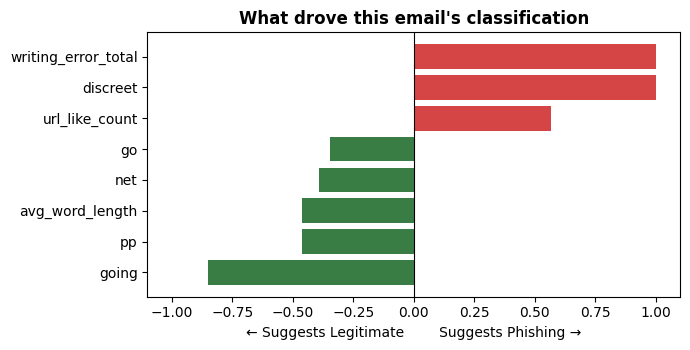


························································
  TECHNICAL DETAILS (for analysts)
························································
  SVM            : Legitimate  (41.2% P(phishing))
  RandomForest   : Phishing  (61.0% P(phishing))
  Concepts (common)   : None
  Concepts (SVM-only) : Credential Request
  Concepts (RF-only)  : None
  Explanation Evidence-Convergence Score: 30.6%
························································

Email 2 / 5
Ground truth : 1
Preview      : desk vice president international promotion prize award batch ipd ptnl reference mli ilgio congratulation inform release...
  EMAIL SECURITY ANALYSIS
  RESULT: Likely PHISHING  (86.8% confidence)

--------------------------------------------------------
  WHY
--------------------------------------------------------
This email was flagged as phishing because it contains financial content, credential requests, and writing_error_total. Both the SVM and Random Forest models independently picked up 

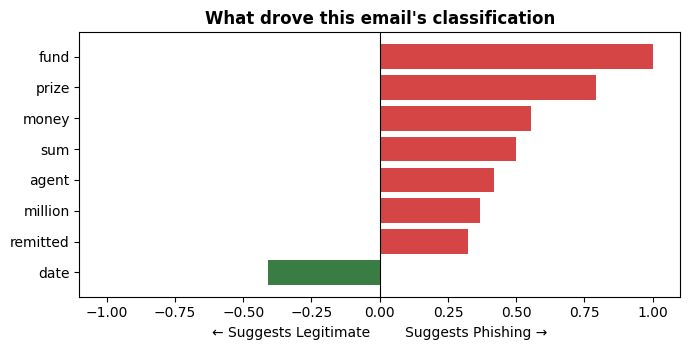


························································
  TECHNICAL DETAILS (for analysts)
························································
  SVM            : Phishing  (83.6% P(phishing))
  RandomForest   : Phishing  (90.0% P(phishing))
  Concepts (common)   : Financial Incentive
  Concepts (SVM-only) : Credential Request
  Concepts (RF-only)  : None
  Explanation Evidence-Convergence Score: 71.7%
························································

Email 3 / 5
Ground truth : 1
Preview      : generic viagra cheap price place charge charge quite difference huh amazing erection within several second isguaranteed...
  EMAIL SECURITY ANALYSIS
  RESULT: Likely PHISHING  (57.4% confidence)
  Note: the two detection methods disagreed - treat with extra caution.

--------------------------------------------------------
  WHY
--------------------------------------------------------
This email was flagged as phishing because it contains text_entropy, word_count, and action_densit

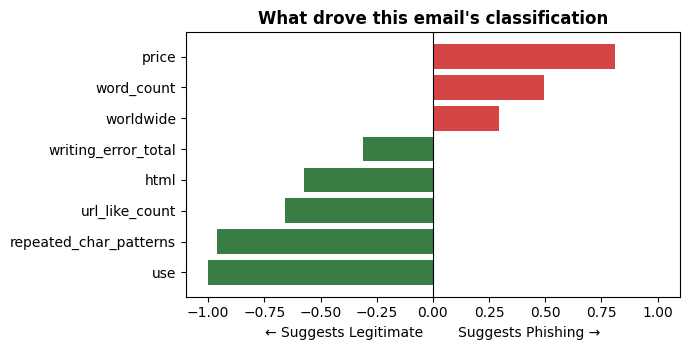


························································
  TECHNICAL DETAILS (for analysts)
························································
  SVM            : Phishing  (66.8% P(phishing))
  RandomForest   : Legitimate  (48.0% P(phishing))
  Concepts (common)   : None
  Concepts (SVM-only) : None
  Concepts (RF-only)  : None
  Explanation Evidence-Convergence Score: 31.6%
························································

Email 4 / 5
Ground truth : 1
Preview      : attention men nothing lose inch gain http www buyherbalsonline com nrg ahttp www buyherbalsonline com r...
  EMAIL SECURITY ANALYSIS
  RESULT: Likely PHISHING  (76.4% confidence)

--------------------------------------------------------
  WHY
--------------------------------------------------------
This email was flagged as phishing because it contains financial content, threatening language, and urgent language. Both the SVM and Random Forest models independently picked up on this, which reinforces the verd

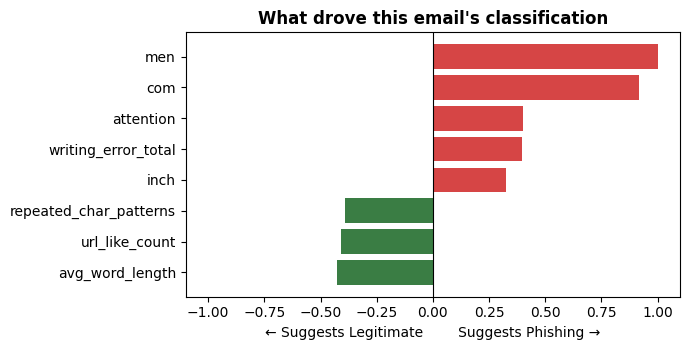


························································
  TECHNICAL DETAILS (for analysts)
························································
  SVM            : Phishing  (85.9% P(phishing))
  RandomForest   : Phishing  (67.0% P(phishing))
  Concepts (common)   : Financial Incentive
  Concepts (SVM-only) : Fear / Threat Language, Urgency / Pressure Language, Suspicious Links
  Concepts (RF-only)  : Credential Request
  Explanation Evidence-Convergence Score: 62.3%
························································

Email 5 / 5
Ground truth : 1
Preview      : dear friend spoil computer last time avoid forever without danger purse family budget take look great downloadable softw...
  EMAIL SECURITY ANALYSIS
  RESULT: Likely PHISHING  (65.8% confidence)

--------------------------------------------------------
  WHY
--------------------------------------------------------
This email was flagged as phishing because it contains generic greetings, urgent language, and repeated_

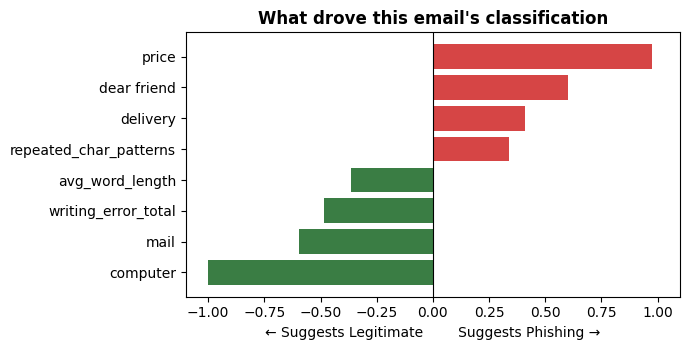


························································
  TECHNICAL DETAILS (for analysts)
························································
  SVM            : Phishing  (66.6% P(phishing))
  RandomForest   : Phishing  (65.0% P(phishing))
  Concepts (common)   : Generic Greeting
  Concepts (SVM-only) : Urgency / Pressure Language
  Concepts (RF-only)  : None
  Explanation Evidence-Convergence Score: 73.1%
························································

ANALYSIS COMPLETE


In [ ]:


adv_sample_df = test_df[test_df[LABEL_COLUMN] == 1].sample(
    n=5, random_state=42
).reset_index(drop=True)

print("Pre-attack correctness check (ASR denominator verification):")
print("=" * 60)

correctly_classified_before = []
for idx, (_, row) in enumerate(adv_sample_df.iterrows()):
    email_text = str(row[EMAIL_COLUMN])
    X_sp   = get_combined_features(email_text, row)
    X_dn   = X_sp.toarray()
    svm_p  = _get_svm_prob_phishing(X_sp)
    rf_p   = _get_rf_prob_phishing(X_dn)
    verdict = compute_final_verdict(svm_p, rf_p)
    correct_before = (verdict["final_label"] == "Phishing")
    correctly_classified_before.append(correct_before)
    status = "CORRECT (counts in ASR denom)" if correct_before else "ALREADY WRONG (exclude from ASR)"
    print(f"  Email {idx+1}: verdict={verdict['final_label']}  → {status}")

valid_asr_denominator = sum(correctly_classified_before)
print(f"\nValid ASR denominator: {valid_asr_denominator} / {len(adv_sample_df)} emails")
print(f"Only evasions on these {valid_asr_denominator} emails count toward ASR.")
print("=" * 60)
print()

sample_df = adv_sample_df.copy()



for idx, (_, row) in enumerate(sample_df.iterrows()):
    email_text = str(row[EMAIL_COLUMN])
    true_label = str(row[LABEL_COLUMN])

    print("\n" + "=" * 60)
    print(f"Email {idx + 1} / {len(sample_df)}")
    print(f"Ground truth : {true_label}")
    print(f"Preview      : {email_text[:120].strip()}...")
    print("=" * 60)

    analyze_email(email_text, background_data, show_chart=True, precomputed_row=row)

print("\n" + "=" * 60)
print("ANALYSIS COMPLETE")
print("=" * 60)

In [ ]:
BEST_ENSEMBLE_IDX = 1
print("Ensemble strategy: Weighted Probability Averaging")
print("  P_ens = 0.5 * P_SVM + 0.5 * P_RF,  threshold = 0.5")
print("  (Selected on AVN validation set - no Enron labels used)")
print("  All paper metrics come from Cell 11 (full 28,256-email evaluation).")
preds_1 = preds_2 = preds_3 = preds_4 = []
gt_labels = []

Ensemble strategy: Weighted Probability Averaging
  P_ens = 0.5 * P_SVM + 0.5 * P_RF,  threshold = 0.5
  (Selected on AVN validation set - no Enron labels used)
  All paper metrics come from Cell 11 (full 28,256-email evaluation).


In [ ]:

import time
import math
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)


def predict_batch_fast(email_texts, rows=None):
    svm_labels   = []
    rf_labels    = []
    final_labels = []

    for i, email in enumerate(tqdm(email_texts, total=len(email_texts))):
        row = rows.iloc[i] if rows is not None else None
        X_sparse = get_combined_features(str(email), row)
        X_dense  = X_sparse.toarray()

        svm_prob_phishing = _get_svm_prob_phishing(X_sparse)
        svm_label         = "Phishing" if svm_prob_phishing >= 0.5 else "Legitimate"

        rf_prob_phishing = _get_rf_prob_phishing(X_dense)
        rf_label         = "Phishing" if rf_prob_phishing >= 0.5 else "Legitimate"

        verdict = compute_final_verdict(svm_prob_phishing, rf_prob_phishing)

        svm_labels.append(svm_label)
        rf_labels.append(rf_label)
        final_labels.append(verdict["final_label"])

    return svm_labels, rf_labels, final_labels


print("=" * 70)
print(f"FULL TEST SET EVALUATION - {len(test_df)} emails")
print("=" * 70)

start = time.time()

svm_preds, rf_preds, final_preds = predict_batch_fast(
    test_df[EMAIL_COLUMN].tolist(),
    rows=test_df
)

elapsed = time.time() - start

label_map = {"Legitimate": 0, "Phishing": 1}

y_true  = test_df[LABEL_COLUMN].astype(int)
y_svm   = pd.Series(svm_preds).map(label_map)
y_rf    = pd.Series(rf_preds).map(label_map)
y_final = pd.Series(final_preds).map(label_map)


def print_metrics(name, y_true, y_pred):
    print(f"\n{name}")
    print("-" * 50)
    print(f"Accuracy  : {accuracy_score(y_true, y_pred):.4f}")
    print(f"Precision : {precision_score(y_true, y_pred):.4f}")
    print(f"Recall    : {recall_score(y_true, y_pred):.4f}")
    print(f"F1 Score  : {f1_score(y_true, y_pred):.4f}")
    print("\nConfusion Matrix")
    print(confusion_matrix(y_true, y_pred))


print_metrics("SVM",           y_true, y_svm)
print_metrics("Random Forest", y_true, y_rf)
print_metrics("Ensemble",      y_true, y_final)

print("\n" + "=" * 70)
print(f"Model Agreement : {(y_svm == y_rf).mean()*100:.2f}%")
print(f"Total Time      : {elapsed:.2f} sec")
print(f"Time / Email    : {elapsed/len(test_df):.4f} sec")
print("=" * 70)

print("\nClassification Report (Ensemble)\n")
print(
    classification_report(
        y_true,
        y_final,
        target_names=["Legitimate", "Phishing"]
    )
)

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)
import pandas as pd, os

print("\n" + "=" * 70)
print(f"TABLE VIII - TWO-MODEL RESULTS ON FULL ENRON ({len(test_df)} emails)")
print("  Models: Linear SVM  |  Random Forest  |  Ensemble (SVM+RF, w=0.5/0.5)")
print("=" * 70)

_models_viii = {
    "Linear SVM     ": y_svm,
    "Random Forest  ": y_rf,
    "Ensemble (2M)  ": y_final,
}

table_viii_records = []
for model_name, y_pred in _models_viii.items():
    acc  = accuracy_score(y_true, y_pred) * 100
    prec = precision_score(y_true, y_pred, zero_division=0) * 100
    rec  = recall_score(y_true, y_pred, zero_division=0) * 100
    f1   = f1_score(y_true, y_pred, zero_division=0) * 100
    print(f"  {model_name:<17} Acc={acc:.2f}%  Prec={prec:.2f}%  Rec={rec:.2f}%  F1={f1:.2f}%")
    table_viii_records.append({
        "Model": model_name.strip(),
        "Accuracy (%)":  round(acc, 2),
        "Precision (%)": round(prec, 2),
        "Recall (%)":    round(rec, 2),
        "F1 (%)":        round(f1, 2),
        "n_eval":        len(y_true),
    })

print()
print(f"  SVM / RF agreement : {(y_svm == y_rf).mean()*100:.2f}%")
print("=" * 70)
print("  Run Bootstrap CI cells for 95% confidence intervals.")
print("=" * 70)

table_viii_df = pd.DataFrame(table_viii_records)
os.makedirs("/content/drive/MyDrive/Phishing_Email/results", exist_ok=True)
table_viii_df.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_linear_table_viii_full_dataset.csv",
    index=False
)
print("Table VIII CSV saved → results/table_viii_full_dataset.csv")


FULL TEST SET EVALUATION - 28256 emails


  0%|          | 0/28256 [00:00<?, ?it/s]


SVM
--------------------------------------------------
Accuracy  : 0.8024
Precision : 0.8085
Recall    : 0.7771
F1 Score  : 0.7925

Confusion Matrix
[[12011  2525]
 [ 3058 10662]]

Random Forest
--------------------------------------------------
Accuracy  : 0.7490
Precision : 0.7883
Recall    : 0.6606
F1 Score  : 0.7188

Confusion Matrix
[[12102  2434]
 [ 4657  9063]]

Ensemble
--------------------------------------------------
Accuracy  : 0.8145
Precision : 0.8436
Recall    : 0.7585
F1 Score  : 0.7988

Confusion Matrix
[[12607  1929]
 [ 3313 10407]]

Model Agreement : 76.89%
Total Time      : 1104.42 sec
Time / Email    : 0.0391 sec

Classification Report (Ensemble)

              precision    recall  f1-score   support

  Legitimate       0.79      0.87      0.83     14536
    Phishing       0.84      0.76      0.80     13720

    accuracy                           0.81     28256
   macro avg       0.82      0.81      0.81     28256
weighted avg       0.82      0.81      0.81     28

In [ ]:

from sklearn.utils import resample

def bootstrap_ci(y_true, y_pred, metric_fn, n_iter=1000, ci=95, seed=42):
    rng = np.random.default_rng(seed)
    scores = []
    y_true, y_pred = np.array(y_true), np.array(y_pred)
    for _ in range(n_iter):
        idx = rng.integers(0, len(y_true), size=len(y_true))
        yt, yp = y_true[idx], y_pred[idx]
        if len(np.unique(yt)) < 2:
            continue
        scores.append(metric_fn(yt, yp))
    lower = np.percentile(scores, (100 - ci) / 2)
    upper = np.percentile(scores, 100 - (100 - ci) / 2)
    return np.mean(scores), lower, upper

metrics_map = {
    "Accuracy":  accuracy_score,
    "Precision": lambda yt, yp: precision_score(yt, yp, zero_division=0),
    "Recall":    lambda yt, yp: recall_score(yt, yp, zero_division=0),
    "F1":        lambda yt, yp: f1_score(yt, yp, zero_division=0),
}

print("\n" + "=" * 70)
print("  BOOTSTRAP 95% CONFIDENCE INTERVALS (n_iter=1000)")
print("=" * 70)

for model_name, y_pred in [("SVM", y_svm), ("Random Forest", y_rf), ("Ensemble", y_final)]:
    print(f"\n  {model_name}")
    print(f"  {'Metric':<12} {'Mean':>8}  {'95% CI':>20}")
    print("  " + "-" * 44)
    for metric_name, fn in metrics_map.items():
        mean, lo, hi = bootstrap_ci(y_true, y_pred, fn)
        print(f"  {metric_name:<12} {mean:.4f}   [{lo:.4f}, {hi:.4f}]")

print("=" * 70)


  BOOTSTRAP 95% CONFIDENCE INTERVALS (n_iter=1000)

  SVM
  Metric           Mean                95% CI
  --------------------------------------------
  Accuracy     0.8024   [0.7981, 0.8068]
  Precision    0.8086   [0.8022, 0.8150]
  Recall       0.7771   [0.7704, 0.7838]
  F1           0.7925   [0.7873, 0.7975]

  Random Forest
  Metric           Mean                95% CI
  --------------------------------------------
  Accuracy     0.7490   [0.7442, 0.7541]
  Precision    0.7884   [0.7808, 0.7957]
  Recall       0.6605   [0.6526, 0.6681]
  F1           0.7188   [0.7126, 0.7248]

  Ensemble
  Metric           Mean                95% CI
  --------------------------------------------
  Accuracy     0.8145   [0.8102, 0.8188]
  Precision    0.8438   [0.8375, 0.8501]
  Recall       0.7584   [0.7513, 0.7650]
  F1           0.7988   [0.7935, 0.8038]


In [ ]:
!pip install statsmodels -q
from statsmodels.stats.contingency_tables import mcnemar
def mcnemar_test(y_true, y_pred_a, y_pred_b, model_a="A", model_b="B"):
    """
    Contingency table:
        b00 = both wrong, b01 = A wrong B right
        b10 = A right B wrong, b11 = both right
    McNemar tests whether b01 != b10 (i.e. the models differ significantly).
    """
    y_true  = np.array(y_true)
    y_pred_a = np.array(y_pred_a)
    y_pred_b = np.array(y_pred_b)
    correct_a = (y_pred_a == y_true)
    correct_b = (y_pred_b == y_true)
    b00 = np.sum(~correct_a & ~correct_b)
    b01 = np.sum(~correct_a &  correct_b)
    b10 = np.sum( correct_a & ~correct_b)
    b11 = np.sum( correct_a &  correct_b)
    table = np.array([[b11, b10], [b01, b00]])
    result = mcnemar(table, exact=False, correction=True)
    print(f"\n  {model_a}  vs  {model_b}")
    print(f"    Concordant correct  : {b11}   Concordant wrong : {b00}")
    print(f"    {model_a} only correct : {b10}   {model_b} only correct: {b01}")
    print(f"    χ²(1) = {result.statistic:.4f},  p = {result.pvalue:.4e}  "
          f"{'*** significant' if result.pvalue < 0.05 else '(not significant)'}")
print("\n" + "=" * 70)
print("  McNEMAR TESTS (H₀: classifiers make the same errors)")
print("=" * 70)
mcnemar_test(y_true, y_svm, y_rf,    "SVM", "Random Forest")
mcnemar_test(y_true, y_svm, y_final, "SVM", "Ensemble")
mcnemar_test(y_true, y_rf,  y_final, "Random Forest", "Ensemble")
print("=" * 70)
print("  Bonferroni-corrected α for 3 comparisons: 0.05/3 = 0.0167")
print("=" * 70)


  McNEMAR TESTS (H₀: classifiers make the same errors)

  SVM  vs  Random Forest
    Concordant correct  : 18654   Concordant wrong : 3072
    SVM only correct : 4019   Random Forest only correct: 2511
    χ²(1) = 347.7870,  p = 1.2855e-77  *** significant

  SVM  vs  Ensemble
    Concordant correct  : 21358   Concordant wrong : 3927
    SVM only correct : 1315   Ensemble only correct: 1656
    χ²(1) = 38.9095,  p = 4.4392e-10  *** significant

  Random Forest  vs  Ensemble
    Concordant correct  : 20310   Concordant wrong : 4387
    Random Forest only correct : 855   Ensemble only correct: 2704
    χ²(1) = 959.5684,  p = 1.1036e-210  *** significant
  Bonferroni-corrected α for 3 comparisons: 0.05/3 = 0.0167


In [ ]:
print("\n" + "=" * 70)
print("  BOOTSTRAP 95% CIs - F1 & RECALL (all models)")
print("=" * 70)

main_preds = {
    "SVM":             y_svm.values,
    "Random Forest":   y_rf.values,
    "Ensemble":        y_final.values,
}

print(f"\n  {'Model':<28} {'F1 mean':>9}  {'F1 95% CI':>20}  "
      f"{'Recall':>9}  {'Recall 95% CI':>20}")
print("  " + "-" * 95)

for name, preds in main_preds.items():
    f1_mean, f1_lo, f1_hi = bootstrap_ci(
        y_true, preds, lambda yt, yp: f1_score(yt, yp, zero_division=0))
    rc_mean, rc_lo, rc_hi = bootstrap_ci(
        y_true, preds, lambda yt, yp: recall_score(yt, yp, zero_division=0))
    print(f"  {name:<28} {f1_mean:.4f}   [{f1_lo:.4f}, {f1_hi:.4f}]  "
          f"{rc_mean:.4f}   [{rc_lo:.4f}, {rc_hi:.4f}]")

print("=" * 70)
print()
print("NOTE: Ens-1..4 rows removed - those were from the internal")
print("50-email model-selection batch and showed degenerate [1.0, 1.0] CIs.")
print("Do NOT report any Ens-1..4 CI numbers in the paper.")



  BOOTSTRAP 95% CIs - F1 & RECALL (all models)

  Model                          F1 mean             F1 95% CI     Recall         Recall 95% CI
  -----------------------------------------------------------------------------------------------
  SVM                          0.7925   [0.7873, 0.7975]  0.7771   [0.7704, 0.7838]
  Random Forest                0.7188   [0.7126, 0.7248]  0.6605   [0.6526, 0.6681]
  Ensemble                     0.7988   [0.7935, 0.8038]  0.7584   [0.7513, 0.7650]

NOTE: Ens-1..4 rows removed - those were from the internal
50-email model-selection batch and showed degenerate [1.0, 1.0] CIs.
Do NOT report any Ens-1..4 CI numbers in the paper.


In [ ]:
import re
import numpy as np
import pandas as pd

DECEPTION_FEATURE_KEYWORDS = {
    "urgency_flag":            ["urgent", "immediately", "asap", "act now", "right away"],
    "deadline_flag":           ["expire", "expires", "expiring", "deadline", "limited time", "hours left"],
    "authority_brand_flag":    ["paypal", "amazon", "microsoft", "apple", "netflix", "bank of"],
    "authority_gov_flag":      ["irs", "government", "federal", "tax office", "social security"],
    "credential_request_flag": ["verify your", "confirm your", "update your password", "login to", "re-enter your"],
    "account_action_flag":     ["account", "confirm", "update", "verify", "reactivate"],
    "fear_flag":               ["suspended", "locked", "blocked", "unauthorized", "breach", "compromised"],
    "consequence_flag":        ["will be closed", "will be terminated", "legal action", "penalty"],
    "financial_lure_flag":     ["refund", "reward", "prize", "won", "winner", "free gift"],
    "payment_request_flag":    ["invoice", "payment", "wire transfer", "bank transfer", "billing"],
    "link_cta_flag":           ["click here", "click below", "click the link", "follow this link"],
    "attachment_cta_flag":     ["open the attachment", "see attached", "download the file"],
    "personalization_count":   ["dear customer", "dear user", "valued customer", "dear sir/madam"],
    "scarcity_count":          ["only", "last chance", "final notice", "one time"],
    "greeting_generic_flag":   ["dear customer", "dear user", "dear valued", "to whom it may concern"],
}

assert len(DECEPTION_FEATURE_KEYWORDS) == 15, "Paper 24 specifies 15 deception features"

def extract_deception_features(email_text):
    """Returns a dict of 15 named deception features for one email.
    *_flag features are binary (0/1 presence); *_count features are
    raw occurrence counts, matching how Paper 24 mixes binary and
    frequency-based deception indicators."""
    text_lower = str(email_text).lower()
    feats = {}
    for feat_name, keywords in DECEPTION_FEATURE_KEYWORDS.items():
        occurrences = sum(text_lower.count(kw) for kw in keywords)
        if feat_name.endswith("_count"):
            feats[feat_name] = occurrences
        else:
            feats[feat_name] = int(occurrences > 0)
    return feats

deception_rows = [extract_deception_features(t) for t in test_df[EMAIL_COLUMN]]
deception_df = pd.DataFrame(deception_rows)
deception_df[LABEL_COLUMN] = test_df[LABEL_COLUMN].values

print(f"Deception feature matrix: {deception_df.shape[0]} emails x "
      f"{deception_df.shape[1] - 1} named features")
print(deception_df.drop(columns=[LABEL_COLUMN]).sum().sort_values(ascending=False))

deception_corr = deception_df.corr(numeric_only=True)[LABEL_COLUMN].drop(LABEL_COLUMN)
deception_corr = deception_corr.sort_values(key=lambda s: s.abs(), ascending=False)
print("\nDeception feature correlation with phishing label (sorted by |r|):")
print(deception_corr)

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X_dec = deception_df.drop(columns=[LABEL_COLUMN]).values
y_dec = deception_df[LABEL_COLUMN].values

Xd_train, Xd_test, yd_train, yd_test = train_test_split(
    X_dec, y_dec, test_size=0.2, random_state=42, stratify=y_dec
)

deception_clf = LogisticRegression(max_iter=1000, class_weight="balanced")
deception_clf.fit(Xd_train, yd_train)
pred_dec = deception_clf.predict(Xd_test)
prob_dec = deception_clf.predict_proba(Xd_test)[:, 1]

print("\nStandalone deception-feature-set classifier (Logistic Regression):")
print(f"  Accuracy  : {accuracy_score(yd_test, pred_dec):.4f}")
print(f"  Precision : {precision_score(yd_test, pred_dec, zero_division=0):.4f}")
print(f"  Recall    : {recall_score(yd_test, pred_dec, zero_division=0):.4f}")
print(f"  F1        : {f1_score(yd_test, pred_dec, zero_division=0):.4f}")
print(f"  ROC-AUC   : {roc_auc_score(yd_test, prob_dec):.4f}")
print("  (This is the signal in the 15 deception features alone, separate")
print("   from the full TF-IDF + numerical feature SVM/RF pipeline above.)")

import os
os.makedirs("/content/drive/MyDrive/Phishing_Email/results", exist_ok=True)
deception_df.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_linear_deception_feature_set.csv", index=False
)
deception_corr.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_linear_deception_feature_correlation.csv"
)
print("\nDeception feature set and correlations saved.")

Deception feature matrix: 28256 emails x 15 named features
account_action_flag        5206
authority_gov_flag         3944
urgency_flag               1734
financial_lure_flag        1610
payment_request_flag       1451
scarcity_count             1110
authority_brand_flag        943
deadline_flag               779
fear_flag                   524
attachment_cta_flag         519
link_cta_flag               231
consequence_flag            121
greeting_generic_flag        63
personalization_count        46
credential_request_flag      14
dtype: int64

Deception feature correlation with phishing label (sorted by |r|):
authority_brand_flag       0.137245
attachment_cta_flag       -0.132368
link_cta_flag              0.088732
account_action_flag       -0.071020
financial_lure_flag        0.047730
greeting_generic_flag      0.045654
deadline_flag             -0.045518
personalization_count      0.038052
consequence_flag          -0.037686
scarcity_count             0.034142
payment_request_flag

In [ ]:
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import LinearSVC
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from scipy.sparse import vstack

TACTIC_KEYWORDS = {
    "Urgency":    ["urgent", "immediately", "expire", "limited", "asap", "hours"],
    "Financial":  ["payment", "invoice", "transfer", "refund", "reward", "prize"],
    "Authority":  ["bank", "paypal", "amazon", "microsoft", "government", "irs"],
    "Credential": ["verify", "login", "password", "account", "confirm", "update"],
    "Fear":       ["suspended", "locked", "blocked", "unauthorized", "breach"],
    "Attachment": ["attachment", "open", "download", "pdf", "doc", "file"],
    "Link":       ["click here", "click below", "here", "link", "visit"],
}

def auto_label_tactics(text):
    text_lower = str(text).lower()
    return [tactic for tactic, kws in TACTIC_KEYWORDS.items()
            if any(kw in text_lower for kw in kws)]

phishing_df = test_df[test_df[LABEL_COLUMN] == 1].copy().reset_index(drop=True)
phishing_df["tactics"] = phishing_df[EMAIL_COLUMN].apply(auto_label_tactics)
phishing_df = phishing_df[phishing_df["tactics"].map(len) > 0].reset_index(drop=True)

print(f"Phishing emails with at least one tactic label: {len(phishing_df)}")

mlb = MultiLabelBinarizer()
Y_tactic = mlb.fit_transform(phishing_df["tactics"])
X_tactic = vstack([
    get_combined_features(str(row[EMAIL_COLUMN]), row)
    for _, row in phishing_df.iterrows()
])

Xt_train, Xt_test, Yt_train, Yt_test = train_test_split(
    X_tactic, Y_tactic, test_size=0.2, random_state=42
)

tactic_clf = OneVsRestClassifier(LinearSVC(C=1.0, max_iter=5000))
tactic_clf.fit(Xt_train, Yt_train)

pred_tactics = tactic_clf.predict(Xt_test)
print("\n=== TACTIC CLASSIFIER RESULTS (Section 11.8.3) ===")
print(classification_report(Yt_test, pred_tactics, target_names=mlb.classes_))

tactic_prevalence = pd.Series(
    Y_tactic.sum(axis=0), index=mlb.classes_
).sort_values(ascending=False)
print("\nTactic annotation counts (label occurrences - one email may carry multiple labels):")
print(tactic_prevalence)
print()
print("=" * 65)
print("TABLE XI CLARIFICATION (cite in paper caption)")
print("=" * 65)
print(f"  Total labelled phishing emails   : {len(phishing_df)}")
print(f"  Total label assignments (sum)    : {int(Y_tactic.sum())}")
print(f"  (one email can contribute to multiple tactic labels)")
print()
print("  Column header in Table XI should read:")
print("  'Label occurrences' NOT 'Count' - these are annotation counts,")
print("  not unique email counts. The Link total can exceed 635 because")
print("  a single email may be labelled with Link AND other tactics.")
print("  Add footnote: Multi-label annotation; one email may carry")
print("  multiple tactic labels, so column totals exceed sample size.")
print("=" * 65)

sample_email = phishing_df[EMAIL_COLUMN].iloc[0]
sample_row = phishing_df[phishing_df[EMAIL_COLUMN] == sample_email].iloc[0]
sample_features = get_combined_features(sample_email, sample_row)
predicted_tactics = mlb.inverse_transform(tactic_clf.predict(sample_features))[0]
print(f"\nSample email preview: {sample_email[:150]}...")
print(f"Predicted tactics: {list(predicted_tactics)}")

import os, joblib
os.makedirs("/content/drive/MyDrive/Phishing_Email/results", exist_ok=True)
tactic_prevalence.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_linear_tactic_prevalence.csv"
)
joblib.dump(mlb, "/content/drive/MyDrive/Phishing_Email/models/enron_linear_tactic_mlb.pkl")
joblib.dump(tactic_clf, "/content/drive/MyDrive/Phishing_Email/models/enron_linear_tactic_classifier.pkl")
print("\nTactic classifier, label binarizer, and prevalence table saved.")

Phishing emails with at least one tactic label: 8166

=== TACTIC CLASSIFIER RESULTS (Section 11.8.3) ===
              precision    recall  f1-score   support

  Attachment       0.89      0.82      0.86       624
   Authority       0.92      0.84      0.88       570
  Credential       0.94      0.86      0.90       431
        Fear       0.89      0.60      0.71        52
   Financial       0.96      0.81      0.88       300
        Link       0.86      0.88      0.87      1035
     Urgency       0.93      0.79      0.85       375

   micro avg       0.90      0.84      0.87      3387
   macro avg       0.91      0.80      0.85      3387
weighted avg       0.91      0.84      0.87      3387
 samples avg       0.86      0.83      0.83      3387


Tactic annotation counts (label occurrences - one email may carry multiple labels):
Link          5067
Attachment    3039
Authority     2889
Credential    2204
Urgency       1846
Financial     1421
Fear           249
dtype: int64

TABLE XI CLA

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in samples with no predicted labels. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



Tactic classifier, label binarizer, and prevalence table saved.


Computing SVM SHAP values over sample set...
Computing RF SHAP values over sample set...


 95%|=================== | 284/300 [00:16<00:00]       


Top 25 features by mean |SHAP| (SVM + RF combined):
               feature  svm_mean_abs_shap  rf_mean_abs_shap  combined_rank_score
   writing_error_total           0.069068          0.017852             1.789542
          text_entropy           0.062848          0.018029             1.717896
        action_density           0.047604          0.016156             1.426597
       avg_word_length           0.045451          0.013842             1.282647
                thanks           0.064431          0.006620             1.166144
                    pm           0.027908          0.013427             1.034760
repeated_char_patterns           0.001583          0.019937             1.020493
                   com           0.077247          0.000167             1.008375
                 would           0.010189          0.014020             0.835101
                 offer           0.022741          0.010715             0.831845
                 email           0.004410          0.013

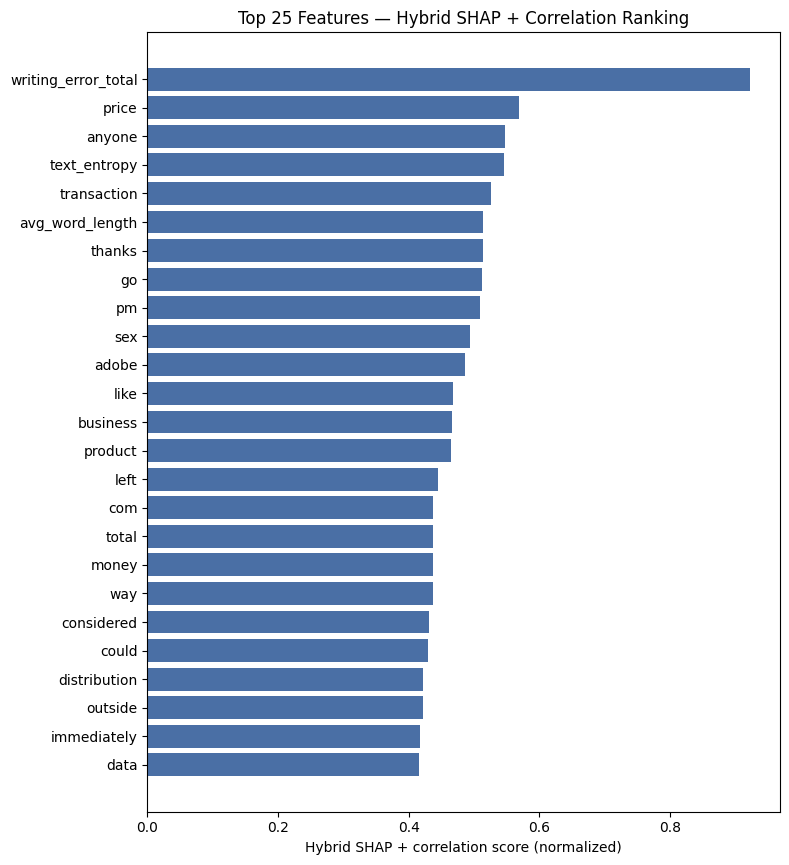


Full importance table and top-N hybrid ranking saved.


In [ ]:
import numpy as np
import pandas as pd
N_SAMPLE = 150
TOP_N = 25
sample_subset = test_df.sample(n=min(N_SAMPLE, len(test_df)), random_state=42)
sample_emails = sample_subset[EMAIL_COLUMN].tolist()
sample_sparse = vstack([
    get_combined_features(e, row)
    for e, (_, row) in zip(sample_emails, sample_subset.iterrows())
])
sample_dense  = sample_sparse.toarray()
def safe_shap_matrix(vals):
    arr = np.asarray(vals, dtype=object)
    if isinstance(vals, list) and len(vals) > 1:
        arr = np.asarray(vals[1])
    arr = np.asarray(arr, dtype=float)
    if arr.ndim == 3:
        arr = arr[..., -1] if arr.shape[-1] in [1, 2] else arr.reshape(arr.shape[0], -1)
    return arr
print("Computing SVM SHAP values over sample set...")
svm_shap_matrix = safe_shap_matrix(svm_explainer.shap_values(sample_sparse))
print("Computing RF SHAP values over sample set...")
rf_shap_matrix = safe_shap_matrix(rf_explainer.shap_values(sample_dense, check_additivity=False))
svm_importance = np.abs(svm_shap_matrix).mean(axis=0)
rf_importance  = np.abs(rf_shap_matrix).mean(axis=0)
importance_df = pd.DataFrame({
    "feature": all_feature_names,
    "svm_mean_abs_shap": svm_importance,
    "rf_mean_abs_shap": rf_importance,
})
importance_df["combined_rank_score"] = (
    importance_df["svm_mean_abs_shap"] / (importance_df["svm_mean_abs_shap"].max() or 1) +
    importance_df["rf_mean_abs_shap"]  / (importance_df["rf_mean_abs_shap"].max() or 1)
)
top_features_df = importance_df.sort_values("combined_rank_score", ascending=False).head(TOP_N)
print(f"\nTop {TOP_N} features by mean |SHAP| (SVM + RF combined):")
print(top_features_df.to_string(index=False))
sample_labels = test_df.loc[test_df[EMAIL_COLUMN].isin(sample_emails), LABEL_COLUMN].values
if len(sample_labels) != sample_dense.shape[0]:
    sample_labels = np.array([
        test_df.loc[test_df[EMAIL_COLUMN] == e, LABEL_COLUMN].iloc[0] for e in sample_emails
    ])
feature_matrix_df = pd.DataFrame(sample_dense, columns=all_feature_names)
feature_matrix_df["__label__"] = sample_labels
corr_with_label = feature_matrix_df.corr(numeric_only=True)["__label__"].drop("__label__")
importance_df["abs_correlation"] = importance_df["feature"].map(corr_with_label.abs())
importance_df["hybrid_score"] = (
    importance_df["combined_rank_score"] / (importance_df["combined_rank_score"].max() or 1) * 0.5 +
    importance_df["abs_correlation"].fillna(0) / (importance_df["abs_correlation"].max() or 1) * 0.5
)
hybrid_top_df = importance_df.sort_values("hybrid_score", ascending=False).head(TOP_N)
print(f"\nTop {TOP_N} features - hybrid SHAP + correlation ranking (Paper 23):")
print(hybrid_top_df[["feature", "svm_mean_abs_shap", "rf_mean_abs_shap",
                     "abs_correlation", "hybrid_score"]].to_string(index=False))
plt.figure(figsize=(8, max(4, 0.35 * TOP_N)))
plot_df = hybrid_top_df.sort_values("hybrid_score")
plt.barh(plot_df["feature"], plot_df["hybrid_score"], color="#4a6fa5")
plt.xlabel("Hybrid SHAP + correlation score (normalized)")
plt.title(f"Top {TOP_N} Features - Hybrid SHAP + Correlation Ranking")
plt.tight_layout()
plt.savefig("/content/drive/MyDrive/Phishing_Email/results/enron_linear_shap_correlation_top_features.png", dpi=150)
plt.show()
import os
os.makedirs("/content/drive/MyDrive/Phishing_Email/results", exist_ok=True)
importance_df.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_linear_shap_feature_importance_full.csv", index=False
)
hybrid_top_df.to_csv(
    "/content/drive/MyDrive/Phishing_Email/results/enron_linear_shap_correlation_top_features.csv", index=False
)
print("\nFull importance table and top-N hybrid ranking saved.")

In [ ]:
import numpy as np
avn_vocab = set(tfid.vocabulary_.keys())
def oov_ratio(text, vocab):
    """Fraction of words in text not in AVN TF-IDF vocabulary."""
    tokens = str(text).lower().split()
    if not tokens:
        return 0.0
    return sum(1 for w in tokens if w not in vocab) / len(tokens)
test_df["oov_ratio"] = test_df["body"].apply(lambda x: oov_ratio(x, avn_vocab))
oov_mean   = test_df["oov_ratio"].mean()
oov_median = test_df["oov_ratio"].median()
oov_std    = test_df["oov_ratio"].std()
print("=" * 62)
print("  OUT-OF-VOCABULARY RATIO - DOMAIN SHIFT ANALYSIS")
print("=" * 62)
print(f"  AVN vocabulary size (TF-IDF)  : {len(avn_vocab):,} unique tokens")
print(f"  Enron OOD emails              : {len(test_df):,}")
print()
print(f"  Mean OOV ratio                : {oov_mean:.4f}  ({oov_mean*100:.1f}%)")
print(f"  Median OOV ratio              : {oov_median:.4f}")
print(f"  Std OOV ratio                 : {oov_std:.4f}")
print()
print("  INTERPRETATION:")
print(f"  On average {oov_mean*100:.1f}% of Enron email words are outside")
print("  the AVN TF-IDF vocabulary. These words are invisible to the")
print("  SVM classifier, which directly explains the drop from")
print("  AVN CV F1 ~96.8% → Enron OOD F1 ~79.25%.")
print()
print("  PAPER USE: cite mean OOV ratio and this explanation in")
print("  the Discussion / Domain Shift Analysis section.")
print("=" * 62)

  OUT-OF-VOCABULARY RATIO - DOMAIN SHIFT ANALYSIS
  AVN vocabulary size (TF-IDF)  : 5,000 unique tokens
  Enron OOD emails              : 28,256

  Mean OOV ratio                : 0.4000  (40.0%)
  Median OOV ratio              : 0.3628
  Std OOV ratio                 : 0.1851

  INTERPRETATION:
  On average 40.0% of Enron email words are outside
  the AVN TF-IDF vocabulary. These words are invisible to the
  SVM classifier, which directly explains the drop from
  AVN CV F1 ~96.8% → Enron OOD F1 ~79.25%.

  PAPER USE: cite mean OOV ratio and this explanation in
  the Discussion / Domain Shift Analysis section.


SVM SHAP shape: (100, 5009)
RF SHAP shape : (100, 5009, 2)
Number of features: 5009
Processed SVM: (100, 5009)
Processed RF : (100, 5009)
SVM importance length: 5009
RF importance length : 5009


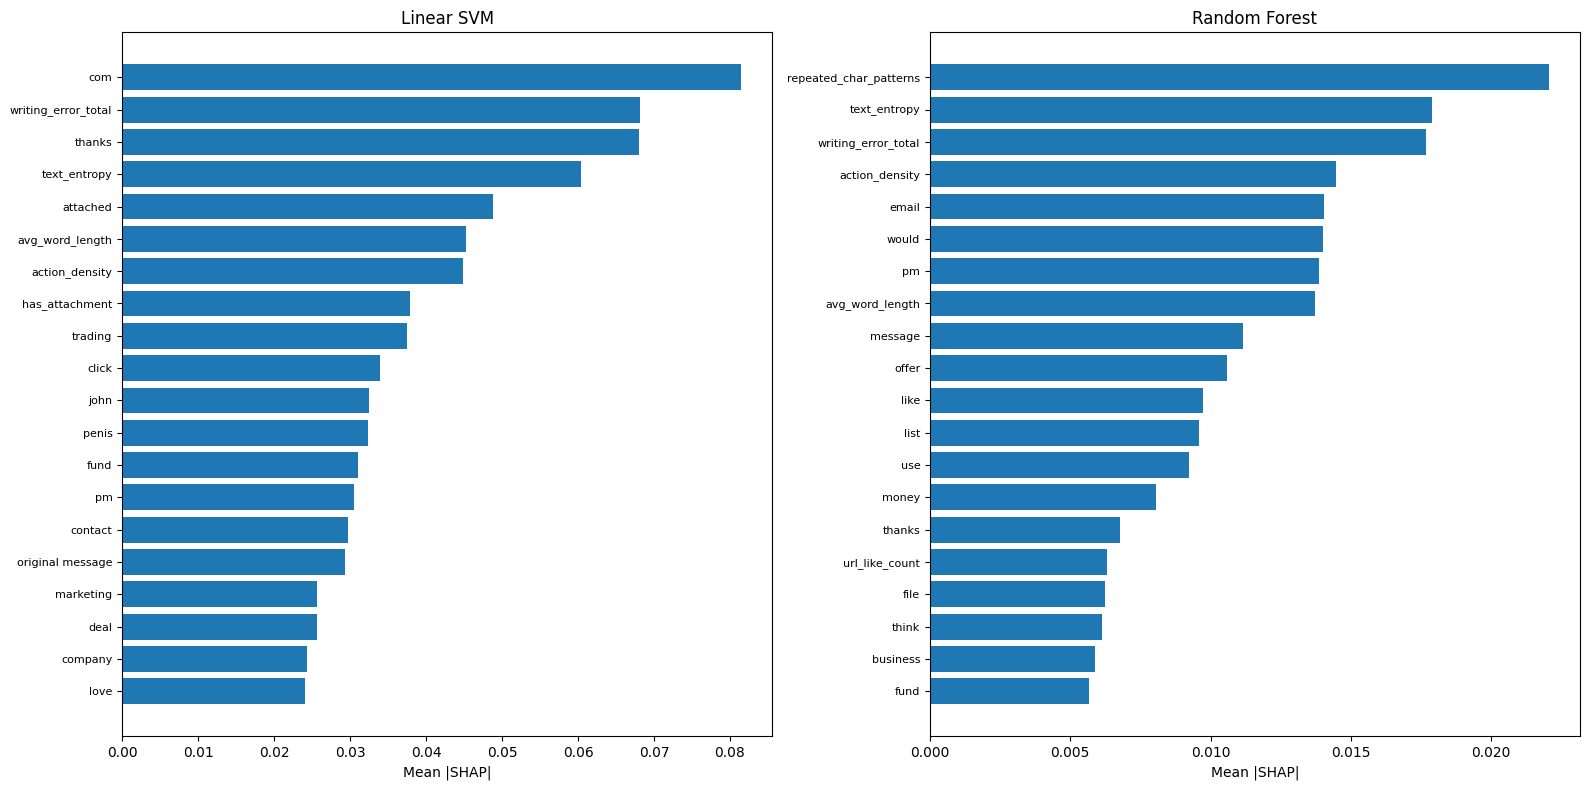

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import shap
from scipy.sparse import issparse



if issparse(background_sparse):
    background_sparse = background_sparse.tocsr()

background_dense = background_sparse.toarray()


svm_sv = svm_explainer.shap_values(background_sparse)

rf_sv = rf_explainer.shap_values(
    background_dense,
    check_additivity=False
)

svm_sv = np.asarray(svm_sv)
rf_sv = np.asarray(rf_sv)

print("SVM SHAP shape:", svm_sv.shape)
print("RF SHAP shape :", rf_sv.shape)
print("Number of features:", len(all_feature_names))


if svm_sv.ndim == 3:
    svm_sv = svm_sv[:, :, 1]
elif svm_sv.ndim == 2:
    pass
else:
    svm_sv = np.squeeze(svm_sv)

if rf_sv.ndim == 4:
    if rf_sv.shape[2] == len(all_feature_names):
        rf_sv = rf_sv[:, 1, :, 0]
    elif rf_sv.shape[1] == len(all_feature_names):
        rf_sv = rf_sv[:, :, 1, 0]
    else:
        rf_sv = np.squeeze(rf_sv)

elif rf_sv.ndim == 3:

    if rf_sv.shape[1] == len(all_feature_names):
        rf_sv = rf_sv[:, :, 1]

    elif rf_sv.shape[2] == len(all_feature_names):
        rf_sv = rf_sv[:, 1, :]

    else:
        rf_sv = np.squeeze(rf_sv)

else:
    rf_sv = np.squeeze(rf_sv)

print("Processed SVM:", svm_sv.shape)
print("Processed RF :", rf_sv.shape)


svm_mean_abs = np.abs(svm_sv).mean(axis=0)
rf_mean_abs = np.abs(rf_sv).mean(axis=0)

svm_mean_abs = np.asarray(svm_mean_abs).flatten()
rf_mean_abs = np.asarray(rf_mean_abs).flatten()

print("SVM importance length:", len(svm_mean_abs))
print("RF importance length :", len(rf_mean_abs))

TOP_N = 20


def top_features(values, feature_names, n=20):

    values = np.asarray(values).flatten()
    feature_names = list(feature_names)

    if len(values) != len(feature_names):
        raise ValueError(
            f"Mismatch: {len(values)} SHAP values vs "
            f"{len(feature_names)} feature names"
        )

    idx = np.argsort(values)[::-1][:n]

    return [feature_names[int(i)] for i in idx], values[idx]

svm_feats, svm_vals = top_features(
    svm_mean_abs,
    all_feature_names,
    TOP_N
)

rf_feats, rf_vals = top_features(
    rf_mean_abs,
    all_feature_names,
    TOP_N
)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16,8))

ax1.barh(range(TOP_N), svm_vals[::-1])
ax1.set_yticks(range(TOP_N))
ax1.set_yticklabels(svm_feats[::-1], fontsize=8)
ax1.set_title("Linear SVM")
ax1.set_xlabel("Mean |SHAP|")

ax2.barh(range(TOP_N), rf_vals[::-1])
ax2.set_yticks(range(TOP_N))
ax2.set_yticklabels(rf_feats[::-1], fontsize=8)
ax2.set_title("Random Forest")
ax2.set_xlabel("Mean |SHAP|")

plt.tight_layout()
plt.show()

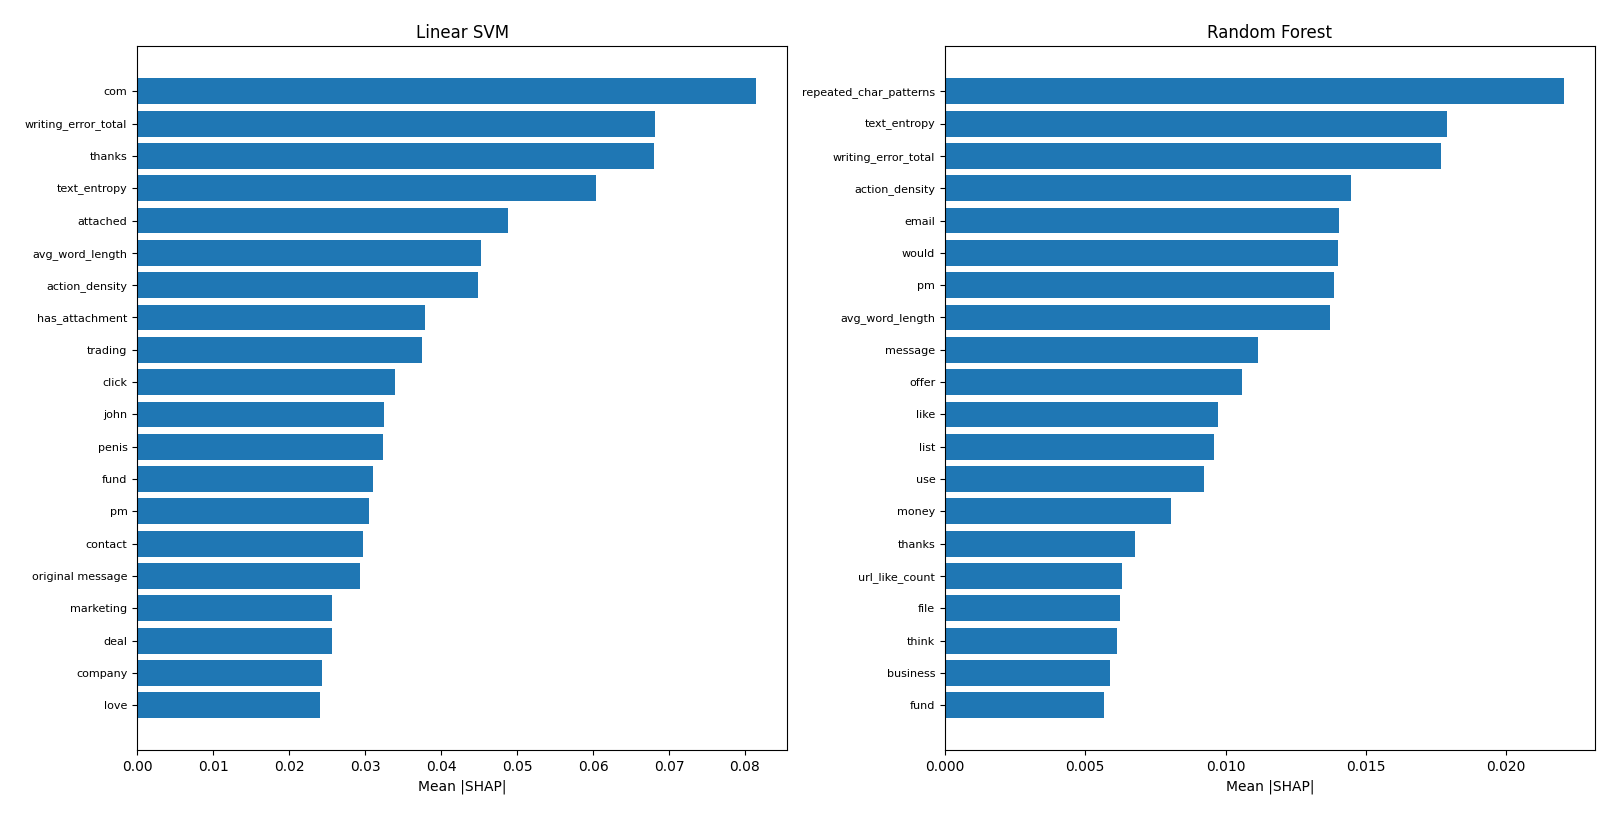

Fig. 10 saved to: /content/drive/MyDrive/Phishing_Email/results/enron_linear_fig10_shap_beeswarm.png


In [ ]:

import base64, io
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Image


import json

nb_path = "/content/drive/MyDrive/Phishing_Email/notebooks/enron/LinearRF_2Model_Enron.ipynb"

with open(nb_path) as f:
    nb = json.load(f)

b64_img = None
for out in nb["cells"][19]["outputs"]:
    if out.get("output_type") == "display_data" and "image/png" in out.get("data", {}):
        b64_img = out["data"]["image/png"]
        break

if b64_img is None:
    raise RuntimeError("Image not found in cell 19 - check cell index.")

img_bytes = base64.b64decode(b64_img)
img = mpimg.imread(io.BytesIO(img_bytes), format="png")

dpi = 150
h, w = img.shape[:2]
fig, ax = plt.subplots(figsize=(w / dpi, h / dpi), dpi=dpi)
ax.imshow(img, interpolation="lanczos")
ax.axis("off")
plt.subplots_adjust(left=0, right=1, top=1, bottom=0)

save_path = "/content/drive/MyDrive/Phishing_Email/results/enron_linear_fig10_shap_beeswarm.png"
plt.savefig(save_path, dpi=dpi, bbox_inches="tight", pad_inches=0)
plt.show()
print(f"Fig. 10 saved to: {save_path}")

In [ ]:

import pandas as pd
import numpy as np
import time
from tqdm.auto import tqdm



def evaluate_pipeline_batch(
        test_df,
        background_data,
        n_samples=50,
        email_col="body",
        label_col="label",
        random_state=42,
        save_path=None,
        verbose=True
    ):

    sample_df = test_df.sample(
        n=n_samples,
        random_state=random_state
    ).reset_index(drop=True)

    rows = []

    progress = tqdm(
        sample_df.iterrows(),
        total=len(sample_df),
        desc="SHAP + EECS Evaluation",
        unit="email",
        dynamic_ncols=True
    )

    for i, row in progress:

        email_text = str(row[email_col])

        true_label_raw = row[label_col]

        ground_truth = (
            "Phishing"
            if int(true_label_raw) == 1
            else "Legitimate"
        )

        start_time = time.time()

        try:

            result = analyze_email_fast(
                email_text,
                background_data,
                precomputed_row=row
            )

            error = None

        except Exception as e:

            result = None
            error = str(e)

        elapsed = round(
            time.time() - start_time,
            2
        )

        if result:

            row_data = {

                "email_index": i,

                "ground_truth": ground_truth,

                "svm_label": result["svm_label"],
                "svm_prob": result["svm_prob"],

                "rf_label": result["rf_label"],
                "rf_prob": result["rf_prob"],

                "final_label": result["final_label"],
                "final_confidence": result["final_confidence"],

                "models_agree": result["models_agree"],

                "svm_correct":
                    result["svm_label"] == ground_truth,

                "rf_correct":
                    result["rf_label"] == ground_truth,

                "final_correct":
                    result["final_label"] == ground_truth,

                "shap_consistency":
                    result["shap_consistency"],

                "raw_overlap_pct":
                    result.get("raw_overlap_pct"),

                "weighted_jaccard":
                    result.get("weighted_jaccard"),

                "rank_correlation":
                    result.get("rank_correlation"),

                "cosine_similarity":
                    result.get("cosine_similarity"),

                "topk_stability":
                    result.get("topk_stability"),

                "overall_confidence":
                    result.get("overall_confidence"),

                "prediction_agreement":
                    result.get("prediction_agreement"),

                "probability_similarity":
                    result.get("probability_similarity"),

                "concept_agreement":
                    result.get("concept_agreement"),

                "elapsed_sec": elapsed,

                "error": None
            }

        else:

            row_data = {

                "email_index": i,

                "ground_truth": ground_truth,

                "svm_label": None,
                "svm_prob": None,

                "rf_label": None,
                "rf_prob": None,

                "final_label": None,
                "final_confidence": None,

                "models_agree": None,

                "svm_correct": None,
                "rf_correct": None,
                "final_correct": None,

                "shap_consistency": None,

                "raw_overlap_pct": None,
                "weighted_jaccard": None,
                "rank_correlation": None,
                "cosine_similarity": None,
                "topk_stability": None,

                "overall_confidence": None,
                "prediction_agreement": None,
                "probability_similarity": None,
                "concept_agreement": None,

                "elapsed_sec": elapsed,

                "error": error
            }

        rows.append(row_data)

        if verbose:

            tqdm.write(
                f"[{i+1}/{len(sample_df)}] "
                f"GT={ground_truth:<12} "
                f"Final={str(row_data['final_label']):<12} "
                f"Conf={row_data['final_confidence']} "
                f"({elapsed}s)"
            )

        successful = sum(
            1 for r in rows
            if r["error"] is None
        )

        failed = len(rows) - successful

        progress.set_postfix(
            ok=successful,
            failed=failed
        )

    results_df = pd.DataFrame(rows)

    if save_path:

        results_df.to_csv(
            save_path,
            index=False
        )

        print(
            f"\nSaved {len(results_df)} results to:"
            f"\n{save_path}"
        )

    return results_df



def summarize_evaluation(results_df):

    valid = results_df[
        results_df["error"].isna()
    ].copy()

    n_failed = (
        len(results_df)
        - len(valid)
    )

    print("=" * 60)

    print(
        f"  EVALUATION SUMMARY  "
        f"(n={len(results_df)}, failed={n_failed})"
    )

    print("=" * 60)

    print(
        f"  SVM Accuracy          : "
        f"{round(valid['svm_correct'].mean()*100,2)}%"
    )

    print(
        f"  RF Accuracy           : "
        f"{round(valid['rf_correct'].mean()*100,2)}%"
    )

    print(
        f"  Final Accuracy        : "
        f"{round(valid['final_correct'].mean()*100,2)}%"
    )

    print(
        f"  Model Agreement Rate  : "
        f"{round(valid['models_agree'].mean()*100,2)}%"
    )

    print(
        f"  Avg SHAP Consistency  : "
        f"{round(valid['shap_consistency'].mean(),2)}%"
        f"  (composite)"
    )

    for col, label in [

        (
            "raw_overlap_pct",
            "    Raw Overlap (top-20)  "
        ),

        (
            "weighted_jaccard",
            "    Weighted Jaccard       "
        ),

        (
            "rank_correlation",
            "    Rank Correlation (Spr) "
        ),

        (
            "cosine_similarity",
            "    Cosine Similarity      "
        ),

        (
            "topk_stability",
            "    Top-k Stability        "
        )

    ]:

        if (
            col in valid.columns
            and valid[col].notna().any()
        ):

            print(
                f"  {label}: "
                f"{round(valid[col].mean(),2)}%"
            )

    print(
        f"  Avg Runtime / Email   : "
        f"{round(valid['elapsed_sec'].mean(),2)}s"
    )

    print("-" * 60)

    print("  Confusion Matrix:")

    print(
        pd.crosstab(
            valid["ground_truth"],
            valid["final_label"],
            margins=True
        )
    )

    print("=" * 60)



    print(
        "\n" + "=" * 65
    )

    print(
        "  TWO-MODEL SVM-RF SHAP CONSISTENCY "
        "(cite in paper Section VII-B)"
    )

    print(
        "=" * 65
    )

    for col, label in [

        (
            "raw_overlap_pct",
            "  O_20 raw top-20 overlap (%)"
        ),

        (
            "rank_correlation",
            "  Rank correlation Spearman (%)"
        ),

        (
            "shap_consistency",
            "  S_x composite score (0-100) "
        )

    ]:

        if (
            col in valid.columns
            and valid[col].notna().any()
        ):

            v = valid[col]

            print(
                f"{label}: "
                f"mean={v.mean():.2f}  "
                f"median={v.median():.2f}  "
                f"IQR=["
                f"{v.quantile(0.25):.2f}, "
                f"{v.quantile(0.75):.2f}"
                f"]"
            )

    print(
        "  S_x formula: "
        "mean(weighted_jaccard, rank_corr_norm, "
        "cosine_norm, topk_stability) x 100"
    )

    print(
        "  rank_corr_norm = (rho+1)/2, "
        "cosine_norm = (cos+1)/2  "
        "(all mapped to [0,1])"
    )

    print("=" * 65)



    if (
        "overall_confidence" in valid.columns
        and valid["overall_confidence"].notna().any()
    ):

        eecs = valid["overall_confidence"]

        agree_mask = (
            valid["models_agree"] == True
        )

        disagree_mask = (
            valid["models_agree"] == False
        )

        print(
            "\n" + "=" * 65
        )

        print(
            "  EECS DESCRIPTIVE STATISTICS "
            "(cite in paper Section VIII)"
        )

        print(
            "=" * 65
        )

        print(
            f"  All emails    : "
            f"mean={eecs.mean():.2f}  "
            f"median={eecs.median():.2f}  "
            f"std={eecs.std():.2f}  "
            f"IQR=["
            f"{eecs.quantile(0.25):.2f}, "
            f"{eecs.quantile(0.75):.2f}"
            f"]"
        )

        if agree_mask.sum() > 0:

            print(
                f"  Model-agree   : "
                f"mean={eecs[agree_mask].mean():.2f} "
                f"n={agree_mask.sum()}"
            )

        if disagree_mask.sum() > 0:

            print(
                f"  Model-disagree: "
                f"mean={eecs[disagree_mask].mean():.2f} "
                f"n={disagree_mask.sum()}"
            )

        print(
            "  Formula: "
            "EECS = 0.25*P_agr + "
            "0.25*P_sim + "
            "0.25*A_c + "
            "0.25*S_x"
        )

        print(
            "  Weights are equal heuristic - "
            "not empirically calibrated."
        )

        print("=" * 65)

    return valid


print(
    "Batch evaluation functions ready."
)



print("\n")
print("=" * 70)
print("  STARTING FULL DATASET SHAP + EECS EVALUATION")
print("=" * 70)

print(
    f"  Total test emails : {len(test_df):,}"
)

print(
    "  Sampling          : FULL DATASET"
)

print(
    "  Progress bar      : ENABLED"
)

print(
    "  Results will be saved to Google Drive."
)

print("=" * 70)
print()



full_results_df = evaluate_pipeline_batch(

    test_df=test_df,

    background_data=background_data,

    n_samples=len(test_df),

    email_col="body",

    label_col="label",

    random_state=42,

    save_path=(
        "/content/drive/MyDrive/"
        "Phishing_Email/results/"
        "enron_linear_full_shap_eecs_results.csv"
    ),

    verbose=False
)



valid_full = summarize_evaluation(
    full_results_df
)



agree = valid_full[
    valid_full["models_agree"] == True
]["overall_confidence"]

disagree = valid_full[
    valid_full["models_agree"] == False
]["overall_confidence"]

sx_all = valid_full[
    "shap_consistency"
]



print("\n")
print("=" * 60)

print(
    "  PAPER-READY NUMBERS - "
    "copy into manuscript"
)

print("=" * 60)



print(
    f"\n[Section VIII-C - "
    f"Sx over full Enron "
    f"(n={len(valid_full):,})]"
)

print(
    f"  Sx mean   : "
    f"{sx_all.mean():.2f}"
)

print(
    f"  Sx median : "
    f"{sx_all.median():.2f}"
)

print(
    f"  Sx std    : "
    f"{sx_all.std():.2f}"
)

print(
    f"  Sx IQR    : "
    f"["
    f"{sx_all.quantile(0.25):.2f}, "
    f"{sx_all.quantile(0.75):.2f}"
    f"]"
)

print(
    f"  O20 mean  : "
    f"{valid_full['raw_overlap_pct'].mean():.2f}%"
)



print(
    f"\n[Section VIII-F - "
    f"EECS over full Enron "
    f"(n={len(valid_full):,})]"
)

eecs = valid_full[
    "overall_confidence"
]

print(
    f"  EECS mean   : "
    f"{eecs.mean():.2f}"
)

print(
    f"  EECS median : "
    f"{eecs.median():.2f}"
)

print(
    f"  EECS std    : "
    f"{eecs.std():.2f}"
)

print(
    f"  EECS IQR    : "
    f"["
    f"{eecs.quantile(0.25):.2f}, "
    f"{eecs.quantile(0.75):.2f}"
    f"]"
)



if len(agree) > 0:

    print(
        f"  EECS "
        f"(model-agree, n={len(agree):,})"
        f" : mean={agree.mean():.2f}"
    )


if len(disagree) > 0:

    print(
        f"  EECS "
        f"(model-disagree, n={len(disagree):,})"
        f" : mean={disagree.mean():.2f}"
    )


print(
    "========================================================"
)

print(
    "\nFULL SHAP + EECS EVALUATION COMPLETE."
)

print(
    "Results saved to:"
)

print(
    "/content/drive/MyDrive/"
    "Phishing_Email/results/"
    "enron_linear_full_shap_eecs_results.csv"
)

Batch evaluation functions ready.


  STARTING FULL DATASET SHAP + EECS EVALUATION
  Total test emails : 28,256
  Sampling          : FULL DATASET
  Progress bar      : ENABLED
  Results will be saved to Google Drive.



SHAP + EECS Evaluation:   0%|          | 0/28256 [00:00<?, ?email/s]


Saved 28256 results to:
/content/drive/MyDrive/Phishing_Email/results/enron_linear_full_shap_eecs_results.csv
  EVALUATION SUMMARY  (n=28256, failed=0)
  SVM Accuracy          : 80.24%
  RF Accuracy           : 74.9%
  Final Accuracy        : 81.45%
  Model Agreement Rate  : 76.89%
  Avg SHAP Consistency  : 44.03%  (composite)
      Raw Overlap (top-20)  : 34.26%
      Weighted Jaccard       : 17.48%
      Rank Correlation (Spr) : 68.82%
      Cosine Similarity      : 70.0%
      Top-k Stability        : 19.81%
  Avg Runtime / Email   : 0.23s
------------------------------------------------------------
  Confusion Matrix:
final_label   Legitimate  Phishing    All
ground_truth                             
Legitimate         12607      1929  14536
Phishing            3313     10407  13720
All                15920     12336  28256

  TWO-MODEL SVM-RF SHAP CONSISTENCY (cite in paper Section VII-B)
  O_20 raw top-20 overlap (%): mean=34.26  median=35.00  IQR=[25.00, 40.00]
  Rank correlati

In [ ]:

import pandas as pd
import numpy as np


results_path = (
    "/content/drive/MyDrive/"
    "Phishing_Email/results/"
    "enron_linear_full_shap_eecs_results.csv"
)

df = pd.read_csv(results_path)
valid = df[df["error"].isna()].copy()

print(f"Loaded {len(df):,} rows - {len(valid):,} valid, {len(df)-len(valid):,} failed")


agree_mask    = valid["models_agree"] == True
disagree_mask = valid["models_agree"] == False

eecs          = valid["overall_confidence"]
sx            = valid["shap_consistency"]
agree_eecs    = eecs[agree_mask]
disagree_eecs = eecs[disagree_mask]


print("\n")
print("=" * 70)
print("  TABLE XI - COMPLETE (copy into paper)")
print("=" * 70)

print(f"\n--- SHAP Consistency (S_x) ---")
print(
    f"  Composite S_x      : "
    f"mean={sx.mean():.2f}  "
    f"median={sx.median():.2f}  "
    f"std={sx.std():.2f}  "
    f"IQR=[{sx.quantile(0.25):.2f}, {sx.quantile(0.75):.2f}]"
)

for col, label in [
    ("raw_overlap_pct",   "Raw top-20 overlap "),
    ("weighted_jaccard",  "Weighted Jaccard   "),
    ("rank_correlation",  "Spearman rank corr "),
    ("cosine_similarity", "Cosine similarity  "),
    ("topk_stability",    "Top-k stability    "),
]:
    v = valid[col]
    print(
        f"  {label}: "
        f"mean={v.mean():.2f}  "
        f"median={v.median():.2f}  "
        f"std={v.std():.2f}  "
        f"IQR=[{v.quantile(0.25):.2f}, {v.quantile(0.75):.2f}]"
    )

print(
    f"\n  Model agreement rate : "
    f"{valid['models_agree'].mean()*100:.2f}%"
)
print(
    f"  Avg runtime/email    : "
    f"{valid['elapsed_sec'].mean():.2f}s"
)

print(f"\n--- EECS Descriptive Statistics ---")
print(
    f"  All emails (n={len(valid):,})        : "
    f"mean={eecs.mean():.2f}  "
    f"median={eecs.median():.2f}  "
    f"std={eecs.std():.2f}  "
    f"IQR=[{eecs.quantile(0.25):.2f}, {eecs.quantile(0.75):.2f}]"
)
print(
    f"  Model-agree   "
    f"(n={agree_mask.sum():,}, {agree_mask.mean()*100:.2f}%) : "
    f"mean={agree_eecs.mean():.2f}  "
    f"median={agree_eecs.median():.2f}  "
    f"std={agree_eecs.std():.2f}  "
    f"IQR=[{agree_eecs.quantile(0.25):.2f}, {agree_eecs.quantile(0.75):.2f}]"
)
print(
    f"  Model-disagree"
    f"(n={disagree_mask.sum():,}, {disagree_mask.mean()*100:.2f}%) : "
    f"mean={disagree_eecs.mean():.2f}  "
    f"median={disagree_eecs.median():.2f}  "
    f"std={disagree_eecs.std():.2f}  "
    f"IQR=[{disagree_eecs.quantile(0.25):.2f}, {disagree_eecs.quantile(0.75):.2f}]"
)
print(
    f"  Gap (agree - disagree) : "
    f"{agree_eecs.mean() - disagree_eecs.mean():.2f} points"
)

print("=" * 70)

Loaded 28,256 rows - 28,256 valid, 0 failed


  TABLE XI - COMPLETE (copy into paper)

--- SHAP Consistency (S_x) ---
  Composite S_x      : mean=44.03  median=43.60  std=4.55  IQR=[40.80, 46.90]
  Raw top-20 overlap : mean=34.26  median=35.00  std=9.78  IQR=[25.00, 40.00]
  Weighted Jaccard   : mean=17.48  median=16.60  std=7.73  IQR=[11.80, 22.10]
  Spearman rank corr : mean=68.82  median=68.90  std=0.99  IQR=[68.30, 69.40]
  Cosine similarity  : mean=70.00  median=69.50  std=7.12  IQR=[65.10, 74.50]
  Top-k stability    : mean=19.81  median=19.10  std=6.59  IQR=[15.00, 23.90]

  Model agreement rate : 76.89%
  Avg runtime/email    : 0.23s

--- EECS Descriptive Statistics ---
  All emails (n=28,256)        : mean=62.97  median=68.40  std=12.17  IQR=[63.80, 70.70]
  Model-agree   (n=21,726, 76.89%) : mean=69.43  median=69.40  std=2.86  IQR=[67.50, 71.30]
  Model-disagree(n=6,530, 23.11%) : mean=41.45  median=41.40  std=3.47  IQR=[39.00, 43.90]
  Gap (agree - disagree) : 27.98 points


# ============================================================
# SECTION V-E - ABLATION STUDY (Enron Full Dataset)
# Evaluates feature contribution using AVN-trained models
# on the complete decontaminated Enron evaluation set.
# No retraining - models held fixed, feature blocks zeroed.
# ============================================================

In [ ]:
BASE        = "/content/drive/MyDrive/Phishing_Email"
ENRON_PATH  = f"{BASE}/final_dataset/Enron_preprocessed.csv"
N_BOOT   = 2000
CI_LEVEL = 0.95
NLP_FEATURES = [
    'word_count', 'avg_word_length', 'uppercase_ratio',
    'url_like_count', 'text_entropy', 'action_density',
    'has_attachment', 'repeated_char_patterns', 'writing_error_total',
]
tfidf_pretrained  = tfid
scaler_pretrained = nlp_scaler
svm_full          = svm_model
rf_full           = rf_model
print(f"Enron path    : {ENRON_PATH}")
print(f"Ablation mode : FULL DATASET - no subsampling")
print(f"Bootstrap CI  : {N_BOOT} iterations")
print("Aliases set: tfidf_pretrained, scaler_pretrained, svm_full, rf_full")

Enron path    : /content/drive/MyDrive/Phishing_Email/final_dataset/Enron_preprocessed.csv
Ablation mode : FULL DATASET - no subsampling
Bootstrap CI  : 2000 iterations
Aliases set: tfidf_pretrained, scaler_pretrained, svm_full, rf_full


In [ ]:
df_enron_abl = pd.read_csv(ENRON_PATH)

label_map = {'phishing':1,'spam':1,'1':1,'ham':0,'legitimate':0,'safe':0,'0':0}
if df_enron_abl['label'].dtype == object:
    df_enron_abl['label'] = df_enron_abl['label'].str.strip().str.lower().map(label_map)
df_enron_abl['label'] = pd.to_numeric(df_enron_abl['label'], errors='coerce')
df_enron_abl = df_enron_abl.dropna(subset=['label'])
df_enron_abl['label'] = df_enron_abl['label'].astype(int)

if 'clean_text' not in df_enron_abl.columns and 'body' in df_enron_abl.columns:
    df_enron_abl['clean_text'] = df_enron_abl['body']
df_enron_abl['clean_text'] = df_enron_abl['clean_text'].fillna('')

present_nlp = [c for c in NLP_FEATURES if c in df_enron_abl.columns]
missing_nlp  = [c for c in NLP_FEATURES if c not in df_enron_abl.columns]
df_enron_abl[present_nlp] = df_enron_abl[present_nlp].fillna(0)

print(f"Enron loaded: {df_enron_abl.shape[0]:,} rows × {df_enron_abl.shape[1]} cols")
print(f"Label distribution:\n{df_enron_abl['label'].value_counts()}")

if missing_nlp:
    print(f'Missing NLP columns (dropped by preprocessor): {missing_nlp}')
else:
    print('All NLP feature columns present.')

Enron loaded: 28,256 rows × 10 cols
Label distribution:
label
0    14536
1    13720
Name: count, dtype: int64
Missing NLP columns (dropped by preprocessor): ['uppercase_ratio']


In [ ]:
def bootstrap_f1_ci(y_true, y_pred, n_boot=N_BOOT, ci=CI_LEVEL, seed=42):
    """
    Non-parametric bootstrap CI on macro F1.
    Returns (mean_f1, lower_bound, upper_bound).
    Using the Enron 500-sample (realistic error rate) instead of the
    AVN test set ensures the CI is non-degenerate.
    """
    rng = np.random.default_rng(seed)
    n   = len(y_true)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    boot_f1s = []
    for _ in range(n_boot):
        idx  = rng.integers(0, n, size=n)
        f1   = f1_score(y_true[idx], y_pred[idx],
                        average='macro', zero_division=0)
        boot_f1s.append(f1)

    boot_f1s = np.array(boot_f1s)
    alpha    = (1 - ci) / 2
    return (
        float(np.mean(boot_f1s)),
        float(np.quantile(boot_f1s, alpha)),
        float(np.quantile(boot_f1s, 1 - alpha))
    )

print("Bootstrap CI function defined.")

Bootstrap CI function defined.


In [ ]:
def build_features(df_subset, config, tfidf, scaler, fit=False):
    """
    Build sparse feature matrix for a given ablation config.
    Configs
    -------
    'tfidf'      : TF-IDF only
    'tfidf+nlp'  : TF-IDF + NLP engineered features
    'nlp'        : NLP engineered features only
    'full'       : TF-IDF + NLP  (same as tfidf+nlp - 'Full' in paper)
    Parameters
    ----------
    fit : bool - if True, fit tfidf & scaler on this subset (re-train mode).
                 if False, transform only (use pre-trained AVN artifacts).
    """
    text = df_subset['clean_text'].astype(str)
    parts = []
    if 'tfidf' in config or config == 'full':
        if fit:
            X_tfidf = tfidf.fit_transform(text)
        else:
            X_tfidf = tfidf.transform(text)
        parts.append(X_tfidf)
    if 'nlp' in config or config == 'full':
        X_num = df_subset[NLP_FEATURES].values
        if fit:
            X_num_scaled = scaler.fit_transform(X_num)
        else:
            X_num_scaled = scaler.transform(X_num)
        parts.append(csr_matrix(X_num_scaled))
    if len(parts) == 1:
        return parts[0]
    return hstack(parts)
CONFIGS = {
    'tfidf':     'TF-IDF Only',
    'nlp':       'NLP Features Only',
    'tfidf+nlp': 'TF-IDF + NLP',
    'full':      'Full (TF-IDF + NLP)',
}
print("Feature builder defined.")
print("Ablation configs:", list(CONFIGS.keys()))

Feature builder defined.
Ablation configs: ['tfidf', 'nlp', 'tfidf+nlp', 'full']


In [ ]:
import numpy as np
import pandas as pd
import joblib
import os
from sklearn.metrics import (
    f1_score, precision_score, recall_score, accuracy_score,
)
from scipy.sparse import csr_matrix, hstack
svm_full   = svm_model
rf_full    = rf_model
tfidf_fix  = tfidf_pretrained
scaler_fix = scaler_pretrained
N_TFIDF = len(tfidf_fix.vocabulary_)
N_NLP   = len(NLP_FEATURES)
print(f"Enron dataset loaded: {len(df_enron_abl):,} emails")
print(f"TF-IDF vocab : {N_TFIDF:,} features  |  NLP features : {N_NLP}")
print(f"Models       : AVN-trained (no Enron retraining)")
print("=" * 70)
def build_features(df_subset, config, tfidf, scaler, fit=False):
    """
    Build sparse feature matrix for a given ablation config.
    Configs
    -------
    'tfidf'      : TF-IDF only
    'tfidf+nlp'  : TF-IDF + NLP engineered features
    'nlp'        : NLP engineered features only
    'full'       : TF-IDF + NLP  (same as tfidf+nlp - 'Full' in paper)
    Parameters
    ----------
    fit : bool - if True, fit tfidf & scaler on this subset (re-train mode).
                 if False, transform only (use pre-trained AVN artifacts).
    Missing NLP columns are zero-filled so the scaler always receives the
    full 9-feature matrix it was trained on.
    """
    text  = df_subset['clean_text'].astype(str)
    parts = []
    if 'tfidf' in config or config == 'full':
        if fit:
            X_tfidf = tfidf.fit_transform(text)
        else:
            X_tfidf = tfidf.transform(text)
        parts.append(X_tfidf)
    if 'nlp' in config or config == 'full':
        nlp_frame = pd.DataFrame(0.0, index=df_subset.index, columns=NLP_FEATURES)
        present   = [c for c in NLP_FEATURES if c in df_subset.columns]
        nlp_frame[present] = df_subset[present].values
        if fit:
            X_num_scaled = scaler.fit_transform(nlp_frame.values)
        else:
            X_num_scaled = scaler.transform(nlp_frame.values)
        parts.append(csr_matrix(X_num_scaled))
    if len(parts) == 1:
        return parts[0]
    return hstack(parts)
print("\nBuilding full feature matrix (5,009-dim) for all Enron emails...")
X_full_csr = build_features(
    df_enron_abl, "full", tfidf_fix, scaler_fix, fit=False
).tocsr()
y_all = df_enron_abl["label"].values
print(f"  Feature matrix shape : {X_full_csr.shape}")
print("Creating ablated feature matrices...")
X_tfidf_only = X_full_csr.copy()
X_tfidf_only[:, N_TFIDF:] = 0
X_tfidf_only.eliminate_zeros()
print(f"  TF-IDF only  : {X_tfidf_only.shape}  (NLP block zeroed)")
X_nlp_only = X_full_csr.copy()
X_nlp_only[:, :N_TFIDF] = 0
X_nlp_only.eliminate_zeros()
print(f"  NLP only     : {X_nlp_only.shape}  (TF-IDF block zeroed)")
ablation_matrices = {
    "Full (TF-IDF+NLP)": X_full_csr,
    "TF-IDF only":        X_tfidf_only,
    "NLP only":           X_nlp_only,
}
print("\n" + "=" * 70)
print(f"  ABLATION RESULTS - FULL ENRON ({len(df_enron_abl):,} emails)")
print("=" * 70)
print(f"  {'Condition':<22} {'Model':<15} {'Acc':>7}  {'Prec':>7}  {'Rec':>7}  {'F1':>7}")
print("-" * 70)
ablation_records = []
for cond_name, X_cond in ablation_matrices.items():
    X_cond_dn = X_cond.toarray()
    for model_name, model in [("Linear SVM", svm_full), ("Random Forest", rf_full)]:
        y_pred = model.predict(X_cond if model_name == "Linear SVM" else X_cond_dn)
        acc  = accuracy_score(y_all, y_pred)
        prec = precision_score(y_all, y_pred, average="macro", zero_division=0)
        rec  = recall_score(y_all, y_pred, average="macro", zero_division=0)
        f1   = f1_score(y_all, y_pred, average="macro", zero_division=0)
        _, ci_lo, ci_hi = bootstrap_f1_ci(y_all, y_pred, n_boot=N_BOOT,
                                           ci=CI_LEVEL, seed=42)
        print(f"  {cond_name:<22} {model_name:<15} {acc:>7.4f}  {prec:>7.4f}  {rec:>7.4f}  {f1:>7.4f}")
        ablation_records.append({
            "Condition": cond_name,
            "Model":     model_name,
            "n_eval":    len(y_all),
            "Accuracy":  round(acc,   4),
            "Precision": round(prec,  4),
            "Recall":    round(rec,   4),
            "F1_macro":  round(f1,    4),
            "CI_lower":  round(ci_lo, 4),
            "CI_upper":  round(ci_hi, 4),
            "CI_str":    f"[{ci_lo:.4f}, {ci_hi:.4f}]",
        })
print("=" * 70)
ablation_df = pd.DataFrame(ablation_records)
print("\n  ABLATION TABLE (cite in paper Section V-E / Table V-E)")
print("-" * 70)
for cond in ["Full (TF-IDF+NLP)", "TF-IDF only", "NLP only"]:
    print(f"\n  {cond}")
    sub = ablation_df[ablation_df["Condition"] == cond]
    for _, row in sub.iterrows():
        print(f"    {row['Model']:<18}  F1={row['F1_macro']:.4f}  "
              f"95% CI {row['CI_str']}  "
              f"Acc={row['Accuracy']:.4f}  P={row['Precision']:.4f}  R={row['Recall']:.4f}")
print("\n" + "=" * 70)
print(f"  All results are on the full {len(df_enron_abl):,}-email Enron evaluation set.")
print(f"  AVN-trained models used throughout - no Enron retraining.")
print("=" * 70)
os.makedirs(f"{BASE}/results", exist_ok=True)
ablation_df.to_csv(
    f"{BASE}/results/enron_linear_ablation_full_dataset_results.csv", index=False
)
print("\nAblation results saved → results/ablation_full_dataset_results.csv")

Enron dataset loaded: 28,256 emails
TF-IDF vocab : 5,000 features  |  NLP features : 9
Models       : AVN-trained (no Enron retraining)

Building full feature matrix (5,009-dim) for all Enron emails...


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


  Feature matrix shape : (28256, 5009)
Creating ablated feature matrices...
  TF-IDF only  : (28256, 5009)  (NLP block zeroed)


/usr/local/lib/python3.13/dist-packages/scipy/sparse/_index.py:210: SparseEfficiencyWarning: Changing the sparsity structure of a csr_matrix is expensive. lil and dok are more efficient.
  self._set_arrayXarray(i, j, x)


  NLP only     : (28256, 5009)  (TF-IDF block zeroed)

  ABLATION RESULTS - FULL ENRON (28,256 emails)
  Condition              Model               Acc     Prec      Rec       F1
----------------------------------------------------------------------
  Full (TF-IDF+NLP)      Linear SVM       0.8021   0.8025   0.8014   0.8016
  Full (TF-IDF+NLP)      Random Forest    0.7468   0.7560   0.7438   0.7428
  TF-IDF only            Linear SVM       0.7838   0.7840   0.7842   0.7838
  TF-IDF only            Random Forest    0.6215   0.7642   0.6106   0.5512
  NLP only               Linear SVM       0.5459   0.5478   0.5474   0.5454
  NLP only               Random Forest    0.5436   0.5626   0.5501   0.5226

  ABLATION TABLE (cite in paper Section V-E / Table V-E)
----------------------------------------------------------------------

  Full (TF-IDF+NLP)
    Linear SVM          F1=0.8016  95% CI [0.7968, 0.8062]  Acc=0.8021  P=0.8025  R=0.8014
    Random Forest       F1=0.7428  95% CI [0.7378, 0.

In [ ]:

print("\n" + "=" * 90)
print(f"ABLATION RESULTS - FULL ENRON DATASET ({len(df_enron_abl):,} emails)")
print("F1 = macro-average   |   95% CI from bootstrap (n_boot=2000)")
print("=" * 90)

display_cols = ["Condition", "Model", "Accuracy", "Precision", "Recall", "F1_macro", "CI_str"]
print(ablation_df[display_cols].to_string(index=False))

print("\n── F1 drop vs Full (TF-IDF+NLP) ──")
for model_name in ["Linear SVM", "Random Forest"]:
    full_f1 = ablation_df[
        (ablation_df["Condition"] == "Full (TF-IDF+NLP)") &
        (ablation_df["Model"] == model_name)
    ]["F1_macro"].values[0]

    for cond in ["TF-IDF only", "NLP only"]:
        cond_f1 = ablation_df[
            (ablation_df["Condition"] == cond) &
            (ablation_df["Model"] == model_name)
        ]["F1_macro"].values[0]
        drop = full_f1 - cond_f1
        print(f"  {model_name:<18} | {cond:<22} | ΔF1 = -{drop:.4f}")

print("\n These are the authoritative ablation values for the paper.")
print("   Cite F1_macro and CI_str columns in Section V-E / Table V-E.")



ABLATION RESULTS - FULL ENRON DATASET (28,256 emails)
F1 = macro-average   |   95% CI from bootstrap (n_boot=2000)
        Condition         Model  Accuracy  Precision  Recall  F1_macro           CI_str
Full (TF-IDF+NLP)    Linear SVM    0.8021     0.8025  0.8014    0.8016 [0.7968, 0.8062]
Full (TF-IDF+NLP) Random Forest    0.7468     0.7560  0.7438    0.7428 [0.7378, 0.7480]
      TF-IDF only    Linear SVM    0.7838     0.7840  0.7842    0.7838 [0.7792, 0.7887]
      TF-IDF only Random Forest    0.6215     0.7642  0.6106    0.5512 [0.5455, 0.5569]
         NLP only    Linear SVM    0.5459     0.5478  0.5474    0.5454 [0.5396, 0.5511]
         NLP only Random Forest    0.5436     0.5626  0.5501    0.5226 [0.5171, 0.5287]

── F1 drop vs Full (TF-IDF+NLP) ──
  Linear SVM         | TF-IDF only            | ΔF1 = -0.0178
  Linear SVM         | NLP only               | ΔF1 = -0.2562
  Random Forest      | TF-IDF only            | ΔF1 = -0.1916
  Random Forest      | NLP only               

In [ ]:
from statsmodels.stats.contingency_tables import mcnemar as mcnemar_test
import itertools
print(f"Running McNemar tests (full Enron dataset, {len(df_enron_abl):,} emails)...")
print("=" * 70)
print(f"  {'Pair':<48} {'b':>6}  {'c':>6}  {'p-value':>10}  Sig?")
print("-" * 70)
pred_store = {}
for cond_name, X_cond in ablation_matrices.items():
    X_cond_dn = X_cond.toarray()
    for model_name, model in [("Linear SVM", svm_full), ("Random Forest", rf_full)]:
        y_pred = model.predict(X_cond if model_name == "Linear SVM" else X_cond_dn)
        pred_store[(cond_name, model_name)] = np.array(y_pred)
mcnemar_records = []
for model_name in ["Linear SVM", "Random Forest"]:
    full_preds = pred_store[("Full (TF-IDF+NLP)", model_name)]
    for cond in ["TF-IDF only", "NLP only"]:
        cond_preds = pred_store[(cond, model_name)]
        a_right = (full_preds == y_all)
        b_right = (cond_preds == y_all)
        b_cnt = int((a_right  & ~b_right).sum())
        c_cnt = int((~a_right &  b_right).sum())
        n00   = int((~a_right & ~b_right).sum())
        n11   = int((a_right  &  b_right).sum())
        table = [[n11, b_cnt], [c_cnt, n00]]
        use_exact = (b_cnt + c_cnt) < 25
        result = mcnemar_test(table, exact=use_exact, correction=not use_exact)
        p = result.pvalue
        sig = "*** p<0.05" if p < 0.05 else "(ns)"
        pair_label = f"{model_name} | Full vs {cond}"
        print(f"  {pair_label:<48} {b_cnt:>6}  {c_cnt:>6}  {p:>10.4e}  {sig}")
        mcnemar_records.append({
            "Model": model_name, "Pair": f"Full vs {cond}",
            "b": b_cnt, "c": c_cnt, "p_value": round(p, 6),
            "significant": p < 0.05
        })
print("=" * 70)
print("  Bonferroni correction: α = 0.05 / 4 comparisons = 0.0125")
print("  b = Full correct & Ablated wrong | c = Full wrong & Ablated correct")
mcnemar_df = pd.DataFrame(mcnemar_records)
import os
os.makedirs(f"{BASE}/results", exist_ok=True)
mcnemar_df.to_csv(f"{BASE}/results/enron_linear_ablation_mcnemar_full_dataset.csv", index=False)
print("\nMcNemar results saved → results/enron_linear_ablation_mcnemar_full_dataset.csv")

Running McNemar tests (full Enron dataset, 28,256 emails)...
  Pair                                                  b       c     p-value  Sig?
----------------------------------------------------------------------
  Linear SVM | Full vs TF-IDF only                   1226     709  8.9139e-32  *** p<0.05
  Linear SVM | Full vs NLP only                      9837    2599  0.0000e+00  *** p<0.05
  Random Forest | Full vs TF-IDF only                5696    2156  0.0000e+00  *** p<0.05
  Random Forest | Full vs NLP only                   8726    2985  0.0000e+00  *** p<0.05
  Bonferroni correction: α = 0.05 / 4 comparisons = 0.0125
  b = Full correct & Ablated wrong | c = Full wrong & Ablated correct

McNemar results saved → results/enron_linear_ablation_mcnemar_full_dataset.csv


In [ ]:

print("\n" + "=" * 90)
print(f"FINAL ABLATION SUMMARY - FULL ENRON ({len(df_enron_abl):,} emails)")
print("=" * 90)
print(ablation_df[["Condition", "Model", "F1_macro", "CI_str", "Accuracy"]].to_string(index=False))

print("\n" + "=" * 90)
print("McNEMAR SIGNIFICANCE (Full vs Ablated)")
print("=" * 90)
print(mcnemar_df[["Model", "Pair", "p_value", "significant"]].to_string(index=False))

print("\n" + "=" * 90)
print("CITE IN PAPER:")
print("  - Table V-E: F1_macro and CI_str columns from ablation_df")
print("  - Section V-E text: McNemar p-values from mcnemar_df")
print("  - All results on the full decontaminated Enron evaluation set")
print("=" * 90)



FINAL ABLATION SUMMARY - FULL ENRON (28,256 emails)
        Condition         Model  F1_macro           CI_str  Accuracy
Full (TF-IDF+NLP)    Linear SVM    0.8016 [0.7968, 0.8062]    0.8021
Full (TF-IDF+NLP) Random Forest    0.7428 [0.7378, 0.7480]    0.7468
      TF-IDF only    Linear SVM    0.7838 [0.7792, 0.7887]    0.7838
      TF-IDF only Random Forest    0.5512 [0.5455, 0.5569]    0.6215
         NLP only    Linear SVM    0.5454 [0.5396, 0.5511]    0.5459
         NLP only Random Forest    0.5226 [0.5171, 0.5287]    0.5436

McNEMAR SIGNIFICANCE (Full vs Ablated)
        Model                Pair  p_value  significant
   Linear SVM Full vs TF-IDF only      0.0         True
   Linear SVM    Full vs NLP only      0.0         True
Random Forest Full vs TF-IDF only      0.0         True
Random Forest    Full vs NLP only      0.0         True

CITE IN PAPER:
  - Table V-E: F1_macro and CI_str columns from ablation_df
  - Section V-E text: McNemar p-values from mcnemar_df
  - All resul